# 07 - RQ4 — Incremental Predictive Value of Geography in Mortgage Denials

**Group 7 | Big Data Analysis Final Project | 2024 HMDA cleaned sample**  
**Input:** `hmda_clean_v1.parquet` | **Target:** `denied` | **Methods:** scikit-learn and Spark MLlib

## Research question and study design

**RQ4:** Does adding state improve held-out denial prediction beyond financial and loan characteristics?

- **Model A (financial and loan predictors):** income, DTI band, CLTV, loan amount, property value, loan term and loan type.
- **Model B (main geographic comparison):** Model A plus state.
- **Model C (separate sensitivity):** Model A plus metropolitan status.
- **Algorithms:** Logistic Regression and Random Forest, in both scikit-learn and Spark MLlib.
- **Intended use:** evaluating incremental predictive information; not individual lending decisions.

The target is 1 for `action_taken = 3` (denied) and 0 for `action_taken = 1` or 2. A single seeded, stratified 80/20 split is saved and used by both frameworks. Learned preprocessing is fitted only on the training sample. The 2024 public LAR lacks an application-date field suitable for a chronological split. Denial reasons, loan pricing/costs, purchaser type, tract fields, engineered missingness indicators, lender ID and demographic variables are excluded from prediction.

## Geographic population conventions (Group 7)

- **Main RQ4 classification:** all **3,140,857** in-scope applications, including states, Washington, D.C., territories and unassigned location codes (denial prevalence approximately **8.81%**). This is also the reference population for loan-type/metro comparisons.
- **Geographic sensitivity:** evaluate the already-trained models on the held-out subset in the **50 U.S. states plus Washington, D.C.**, matching the RQ1/RQ3 geography reference population (3,119,941 total in-scope records, raw denial prevalence approximately **8.62%**). This sensitivity does **not** retrain models.
- Neither 8.62% nor 8.81% is subtracted from ROC-AUC. The geographic reference rate convention applies to descriptive **denial-rate gaps**, not model discrimination statistics.

Preprocessing and model settings are held constant in the main A/B/C experiment. In addition to train–test diagnostics and paired bootstrap CIs, the notebook audits outcome-dependent predictor missingness and refits **only scikit-learn Logistic A/B** on applications with an observed DTI band as a *separate* leakage robustness analysis. This sensitivity does not replace the core cross-framework comparison.

**Important reporting conventions:** PR-AUC is reported as *Average Precision*; the prespecified practically relevant ROC-AUC gain is +0.01. Single-run model-fit timings in local Colab are exploratory and **not** the group's repeated 25%/50%/100% Pandas–Spark performance benchmark. All results are associative, not causal or evidence of discrimination.

## 1. Environment and Google Drive access

Run the notebook from top to bottom. The cleaned Parquet file is reused; this notebook does not repeat cleaning or modify the original dataset.

In [1]:
%pip -q install pyarrow scikit-learn

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import os
import gc
import time
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)

RANDOM_SEED = 2026
TEST_SIZE = 0.20
DECISION_THRESHOLD = 0.50
PRACTICAL_ROC_AUC_GAIN = 0.01

N_BOOTSTRAP = 200
BOOTSTRAP_SAMPLE_SIZE = 150_000
TRAIN_EVAL_SIZE = 150_000

from datetime import datetime, timezone
RUN_STARTED_UTC = datetime.now(timezone.utc).isoformat(timespec="seconds")
# Group 7 shared Drive folder "hmda" (same folder as the cleaned data and the other notebooks)
HMDA_DIR = Path("/content/drive/MyDrive/hmda")
if not HMDA_DIR.exists():
    print("WARNING: folder 'hmda' not found in My Drive - add the shared folder as a shortcut to My Drive. Outputs go to a new 'hmda' folder.")
OUTPUT_DIR = HMDA_DIR / "results" / "rq4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Environment initialized.")
print("Random seed:", RANDOM_SEED)
print("Test size:", TEST_SIZE)
print("Output directory:", OUTPUT_DIR)
print("Run started (UTC):", RUN_STARTED_UTC)

# Group 7 — Official chart system
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

COLORS = {
    "amber": "#F6AE2D",
    "orange": "#F28C28",
    "terracotta": "#E4572E",
    "denied": "#D94F30",
    "deep_red": "#B83227",
    "burgundy": "#8C2F39",
    "cream": "#FFF9F2",
    "text": "#422A24",
    "secondary": "#77665F",
    "grid": "#EADFD5",
    "missing": "#B8B8B8",
    "white": "#FFFFFF",
}

OUTCOME_COLORS = {
    "Denied": COLORS["denied"],
    "Originated or approved": COLORS["amber"],
}
LOAN_TYPE_COLORS = {
    "Conventional": COLORS["amber"],
    "FHA": COLORS["orange"],
    "VA": COLORS["terracotta"],
    "USDA/RHS/FSA": COLORS["burgundy"],
}
HEATMAP_CMAP = LinearSegmentedColormap.from_list(
    "group7_warm",
    ["#FFF4E6", "#FFD58A", "#F6AE2D", "#F28C28", "#E4572E", "#B83227"],
)
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 16, "axes.titleweight": "bold", "axes.labelsize": 12,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 11,
    "figure.figsize": (10, 5.5), "figure.dpi": 120, "savefig.dpi": 300,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": COLORS["grid"], "axes.labelcolor": COLORS["text"],
    "text.color": COLORS["text"], "xtick.color": COLORS["secondary"],
    "ytick.color": COLORS["secondary"],
    "figure.facecolor": COLORS["white"], "axes.facecolor": COLORS["white"],
    "axes.grid": False,
})

def style_statistical_axes(ax, axis="x"):
    ax.grid(axis=axis, color=COLORS["grid"], linewidth=0.7)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    return ax

Mounted at /content/drive
Environment initialized.
Random seed: 2026
Test size: 0.2
Output directory: /content/drive/MyDrive/hmda/results/rq4
Run started (UTC): 2026-11-23T09:34:12+00:00


## 2. Load and validate the cleaned analytical sample

The cleaned Parquet already contains the proposal's in-scope sample. `action_taken` is used only to validate the target and is removed before model fitting. It is never used as a predictor.

In [2]:
DRIVE_ROOT = Path("/content/drive/MyDrive")

expected_paths = [
    DRIVE_ROOT / "hmda" / "hmda_clean_v1" / "hmda_clean_v1.parquet",   # shared group folder first
    DRIVE_ROOT / "hmda_clean_v1" / "hmda_clean_v1.parquet",
    DRIVE_ROOT / "hmda_clean_v1.parquet"
]

DATA_PATH = next((p for p in expected_paths if p.is_file()), None)

if DATA_PATH is None:
    matches = list(DRIVE_ROOT.rglob("hmda_clean_v1.parquet"))
    if not matches:
        matches = list(DRIVE_ROOT.rglob("hmda_clean_v1.parquet.bin"))
    if len(matches) == 0:
        raise FileNotFoundError(
            "hmda_clean_v1.parquet was not found in My Drive. "
            "Add the shared cleaned-data folder as a My Drive shortcut."
        )
    if len(matches) > 1:
        print("Multiple matching files were found:")
        for path in matches:
            print(path)
        raise RuntimeError(
            "Multiple cleaned Parquet files were found. Set DATA_PATH explicitly."
        )
    DATA_PATH = matches[0]

print("Dataset:", DATA_PATH)
print(f"File size: {DATA_PATH.stat().st_size / (1024 ** 2):.2f} MB")

REQUIRED_COLUMNS = [
    "action_taken",
    "denied",
    "income",
    "dti_band",
    "combined_loan_to_value_ratio",
    "loan_amount",
    "property_value",
    "loan_term",
    "loan_type",
    "state_code",
    "metro_flag"
]

import pyarrow.parquet as pq
available_columns = pq.ParquetFile(DATA_PATH).schema.names
missing_columns = [c for c in REQUIRED_COLUMNS if c not in available_columns]

if missing_columns:
    raise KeyError(f"Required RQ4 columns are missing: {missing_columns}")

# Read only the columns needed for RQ4.
rq4_raw = pd.read_parquet(
    DATA_PATH,
    columns=REQUIRED_COLUMNS,
    engine="pyarrow"
)

print(f"Records loaded: {len(rq4_raw):,}")
print(f"Columns loaded: {rq4_raw.shape[1]:,}")
display(rq4_raw.head())


Dataset: /content/drive/MyDrive/hmda/hmda_clean_v1/hmda_clean_v1.parquet
File size: 45.10 MB
Records loaded: 3,140,857
Columns loaded: 11


,action_taken,denied,income,dti_band,combined_loan_to_value_ratio,loan_amount,property_value,loan_term,loan_type,state_code,metro_flag
0,1,0,111.0,40-<45,76.744,335000,435000.0,360.0,3,TX,1
1,1,0,83.0,50-60,96.500,265000,275000.0,360.0,2,OK,1
2,1,0,91.0,30-<36,80.000,215000,265000.0,360.0,1,TX,1
3,1,0,134.0,40-<45,95.000,315000,335000.0,360.0,1,IN,1
4,1,0,178.0,30-<36,95.000,365000,385000.0,360.0,1,TX,1


## 3. Define the target and permitted predictors

The feature list follows the final proposal exactly.

| Specification | Predictors |
|---|---|
| Model A | Income, DTI band, CLTV, loan amount, property value, loan term, loan type |
| Model B | Model A plus state |
| Model C | Model A plus metro status, evaluated separately |

Continuous variables are retained as continuous inputs. Income, loan amount and property value are log-transformed because their distributions are strongly right-skewed. DTI band and loan type are categorical. CLTV and loan term remain continuous.

Numeric missing values are median-imputed without adding missingness indicators. The `Missing` level already present in `dti_band` is retained as part of the specified DTI-band variable.

In [3]:
# Validate the decision sample and target definition.
rq4_raw["action_taken"] = pd.to_numeric(
    rq4_raw["action_taken"], errors="raise"
).astype("int8")

rq4_raw["denied"] = pd.to_numeric(
    rq4_raw["denied"], errors="raise"
).astype("int8")

action_values = set(rq4_raw["action_taken"].unique())
if not action_values.issubset({1, 2, 3}):
    raise ValueError(
        f"The cleaned in-scope sample should contain action_taken 1, 2, 3 only. "
        f"Found: {action_values}"
    )

target_matches_action = (
    rq4_raw["denied"].to_numpy()
    == (rq4_raw["action_taken"].to_numpy() == 3).astype("int8")
).all()

if not target_matches_action:
    raise ValueError(
        "The denied target does not match action_taken == 3."
    )

if rq4_raw["denied"].isna().any():
    raise ValueError("The target contains missing values.")

if not set(rq4_raw["denied"].unique()).issubset({0, 1}):
    raise ValueError("The target must be binary.")

LOG_NUMERIC = ["income", "loan_amount", "property_value"]
LINEAR_NUMERIC = [
    "combined_loan_to_value_ratio",
    "loan_term"
]
BASE_CATEGORICAL = ["dti_band", "loan_type"]

MODEL_SPECS = {
    "A": {
        "description": "Financial and loan characteristics",
        "extra_categorical": []
    },
    "B": {
        "description": "Model A plus state",
        "extra_categorical": ["state_code"]
    },
    "C": {
        "description": "Model A plus metro status",
        "extra_categorical": ["metro_flag"]
    }
}

# Check that log-transformed inputs are non-negative.
for col in LOG_NUMERIC:
    values = pd.to_numeric(rq4_raw[col], errors="coerce").dropna()
    if (values < 0).any():
        raise ValueError(
            f"{col} contains negative values; review the cleaning rule before log1p."
        )

# Build a compact modelling table. action_taken is deliberately not retained.
model_data = rq4_raw[
    [
        "denied",
        "income",
        "dti_band",
        "combined_loan_to_value_ratio",
        "loan_amount",
        "property_value",
        "loan_term",
        "loan_type",
        "state_code",
        "metro_flag"
    ]
].copy()

model_data.insert(
    0,
    "row_id",
    np.arange(len(model_data), dtype=np.int64)
)

model_data["denied"] = model_data["denied"].astype("int8")

for col in LOG_NUMERIC + LINEAR_NUMERIC:
    model_data[col] = pd.to_numeric(
        model_data[col], errors="coerce"
    ).astype("float64")

ALL_CATEGORICAL = (
    BASE_CATEGORICAL + ["state_code", "metro_flag"]
)

for col in ALL_CATEGORICAL:
    model_data[col] = (
        model_data[col]
        .astype("string")
        .fillna("Missing")
        .astype(str)
    )

# The literal HMDA code "NA" is an unrecognized/unknown geography code,
# not a U.S. state. Keep those records but label the category explicitly.
model_data["state_code"] = model_data["state_code"].replace(
    {"NA": "Unknown/NA"}
)

print("Target validation passed:", target_matches_action)
print(f"Total records: {len(model_data):,}")
print(f"Denied records: {int(model_data['denied'].sum()):,}")
print(f"Denial rate: {model_data['denied'].mean():.4%}")

print("\nTarget distribution:")
display(
    model_data["denied"]
    .value_counts()
    .sort_index()
    .rename_axis("denied")
    .to_frame("records")
)

print("\nMissing numeric values before imputation:")
display(
    model_data[LOG_NUMERIC + LINEAR_NUMERIC]
    .isna()
    .sum()
    .rename("missing_records")
    .to_frame()
)


Target validation passed: True
Total records: 3,140,857
Denied records: 276,604
Denial rate: 8.8066%

Target distribution:


,records
denied,
0,2864253
1,276604



Missing numeric values before imputation:


,missing_records
income,38308
loan_amount,0
property_value,29441
combined_loan_to_value_ratio,97627
loan_term,7165


## 4. Predictor missingness and reporting-process audit

This audit describes the relationship between **observed missingness and the reported denial outcome**, including the DTI `Missing` band. It is descriptive, not a data-leakage diagnosis by itself. HMDA Regulation C requires underwriting fields such as DTI/CLTV to be reported when relied on in credit decisions; `NA` or `Exempt` may reflect a reporting or underwriting process. The main models retain the proposal's defined variables; no additional missingness-indicator predictors are created.

Source: [CFPB, HMDA Regulation C § 1003.4](https://www.consumerfinance.gov/rules-policy/regulations/1003/4/). Missingness differences alone cannot establish whether information was available at the intended prediction time.

In [4]:
# Descriptive leakage audit (NOT predictors and NOT model training).
NUMERIC_AUDIT = LOG_NUMERIC + LINEAR_NUMERIC
CATEGORICAL_AUDIT = ["dti_band", "loan_type", "state_code", "metro_flag"]
MISSING_MARKERS = {"Missing", "NA", "Exempt", "Unknown/NA", "", "nan", "None"}

missingness_audit_rows = []
for variable in NUMERIC_AUDIT + CATEGORICAL_AUDIT:
    if variable in NUMERIC_AUDIT:
        missing_mask = model_data[variable].isna()
    else:
        missing_mask = model_data[variable].astype(str).str.strip().isin(MISSING_MARKERS)

    rates = {}
    for value, outcome_name in [(0, "non_denied"), (1, "denied")]:
        outcome_mask = model_data["denied"].eq(value)
        rates[f"{outcome_name}_records"] = int(outcome_mask.sum())
        rates[f"missing_{outcome_name}_n"] = int((outcome_mask & missing_mask).sum())
        rates[f"missing_{outcome_name}_pct"] = float(missing_mask.loc[outcome_mask].mean() * 100)

    missingness_audit_rows.append({
        "variable": variable,
        "missing_definition": (
            "Null numeric" if variable in NUMERIC_AUDIT
            else "Explicit unavailable / missing category"
        ),
        "total_missing_n": int(missing_mask.sum()),
        "total_missing_pct": float(missing_mask.mean() * 100),
        **rates,
        "missing_rate_difference_denied_minus_non_denied_pp": (
            rates["missing_denied_pct"] - rates["missing_non_denied_pct"]
        )
    })

missingness_audit = pd.DataFrame(missingness_audit_rows)
print("Predictor unavailability by observed outcome (% of each outcome group):")
display(missingness_audit)

# Preserve cleaning_rules.md's DTI band conventions; missing stays a group.
DTI_ORDER = [
    "<20", "20-<30", "30-<36", "36-<40",
    "40-<45", "45-<50", "50-60", ">60", "Missing"
]
dti_band_denial_rates = (
    model_data.groupby("dti_band", dropna=False)["denied"]
    .agg(decisions="size", denied="sum")
    .reset_index()
)
dti_band_denial_rates["denial_rate"] = (
    dti_band_denial_rates["denied"] / dti_band_denial_rates["decisions"]
)
dti_band_denial_rates["rank"] = (
    dti_band_denial_rates["dti_band"].map({b: j for j, b in enumerate(DTI_ORDER)})
)
dti_band_denial_rates = (
    dti_band_denial_rates.sort_values(["rank", "dti_band"], na_position="last")
    .drop(columns="rank").reset_index(drop=True)
)
print("\nDenial rate by DTI band (including Missing):")
display(dti_band_denial_rates)

DTI_MISSING_MARKERS = {"Missing", "NA", "Exempt", "", "nan", "None"}
DTI_MISSING_MASK = model_data["dti_band"].astype(str).str.strip().isin(DTI_MISSING_MARKERS)
print(f"\nDTI-unavailable records: {int(DTI_MISSING_MASK.sum()):,} ({DTI_MISSING_MASK.mean():.2%}).")
print("Audit interpretation: outcome-associated reporting is not, by itself, proof of leakage.")

Predictor unavailability by observed outcome (% of each outcome group):


,variable,missing_definition,total_missing_n,total_missing_pct,non_denied_records,missing_non_denied_n,missing_non_denied_pct,denied_records,missing_denied_n,missing_denied_pct,missing_rate_difference_denied_minus_non_denied_pp
0,income,Null numeric,38308,1.219667,2864253,28328,0.989019,276604,9980,3.608046,2.619027
1,loan_amount,Null numeric,0,0.000000,2864253,0,0.000000,276604,0,0.000000,0.000000
2,property_value,Null numeric,29441,0.937356,2864253,15588,0.544226,276604,13853,5.008243,4.464017
3,combined_loan_to_value_ratio,Null numeric,97627,3.108292,2864253,81981,2.862212,276604,15646,5.656462,2.794250
4,loan_term,Null numeric,7165,0.228122,2864253,3951,0.137942,276604,3214,1.161950,1.024008
5,dti_band,Explicit unavailable / missing category,25138,0.800355,2864253,16517,0.576660,276604,8621,3.116730,2.540070
6,loan_type,Explicit unavailable / missing category,0,0.000000,2864253,0,0.000000,276604,0,0.000000,0.000000
7,state_code,Explicit unavailable / missing category,8026,0.255535,2864253,2791,0.097443,276604,5235,1.892597,1.795155
8,metro_flag,Explicit unavailable / missing category,0,0.000000,2864253,0,0.000000,276604,0,0.000000,0.000000



Denial rate by DTI band (including Missing):


,dti_band,decisions,denied,denial_rate
0,<20,113535,12557,0.110600
1,20-<30,390684,18508,0.047373
2,30-<36,449579,20620,0.045865
3,36-<40,401994,19624,0.048817
4,40-<45,628198,33223,0.052886
5,45-<50,710151,41881,0.058975
6,50-60,338631,55306,0.163322
7,>60,82947,66264,0.798872
8,Missing,25138,8621,0.342947



DTI-unavailable records: 25,138 (0.80%).
Audit interpretation: outcome-associated reporting is not, by itself, proof of leakage.


## 5. Create one shared stratified 80/20 split

The split is created once in Pandas using the target for stratification and a fixed random seed. The resulting train and test Parquet files are then reused by scikit-learn and Spark MLlib. This guarantees that both frameworks evaluate the same records.

The test set is held out until model fitting and preprocessing are complete. It is not used for model selection or tuning.

A fixed, stratified 150,000-record subset of training applications is used only for training-fit diagnostics. It is never used for tuning, and the full held-out test set remains the primary evaluation sample.

In [5]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    model_data,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
    stratify=model_data["denied"]
)

train_df = train_df.sort_values("row_id").reset_index(drop=True)
test_df = test_df.sort_values("row_id").reset_index(drop=True)

SPLIT_DIR = Path("/content/rq4_shared_splits")      # local working copies; not saved to results/
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_PATH = SPLIT_DIR / "rq4_train_split.parquet"
TEST_PATH = SPLIT_DIR / "rq4_test_split.parquet"

train_df.to_parquet(TRAIN_PATH, index=False, engine="pyarrow")
test_df.to_parquet(TEST_PATH, index=False, engine="pyarrow")

split_summary = pd.DataFrame([
    {
        "split": "Training",
        "records": len(train_df),
        "denied_records": int(train_df["denied"].sum()),
        "denial_rate": float(train_df["denied"].mean())
    },
    {
        "split": "Held-out test",
        "records": len(test_df),
        "denied_records": int(test_df["denied"].sum()),
        "denial_rate": float(test_df["denied"].mean())
    }
])

display(split_summary)

print("Training split saved:", TRAIN_PATH)
print("Test split saved:", TEST_PATH)
print("The same two files will be used by both modelling frameworks.")

# A single training-only evaluation subsample, reused in both frameworks.
from sklearn.model_selection import StratifiedShuffleSplit
train_eval_n = min(TRAIN_EVAL_SIZE, len(train_df))
if train_eval_n == len(train_df):
    train_eval_df = train_df.copy()
else:
    splitter = StratifiedShuffleSplit(
        n_splits=1, train_size=train_eval_n, random_state=RANDOM_SEED + 17
    )
    sample_indices, _ = next(splitter.split(train_df, train_df["denied"]))
    train_eval_df = train_df.iloc[sample_indices].copy()
train_eval_df = train_eval_df.sort_values("row_id").reset_index(drop=True)
TRAIN_EVAL_PATH = SPLIT_DIR / "rq4_train_evaluation_subset.parquet"
train_eval_df.to_parquet(TRAIN_EVAL_PATH, index=False, engine="pyarrow")
train_eval_summary = pd.DataFrame([{
    "records": int(len(train_eval_df)),
    "denied_records": int(train_eval_df["denied"].sum()),
    "denial_rate": float(train_eval_df["denied"].mean()),
    "role": "Training-set generalization diagnostic (not model selection)"
}])
print("\nFixed training evaluation sample:")
display(train_eval_summary)


,split,records,denied_records,denial_rate
0,Training,2512685,221283,0.088066
1,Held-out test,628172,55321,0.088067


Training split saved: /content/rq4_shared_splits/rq4_train_split.parquet
Test split saved: /content/rq4_shared_splits/rq4_test_split.parquet
The same two files will be used by both modelling frameworks.

Fixed training evaluation sample:


,records,denied_records,denial_rate,role
0,150000,13210,0.088067,Training-set generalization diagnostic (not mo...


## 6. Model specification and evaluation metrics

The outcome is imbalanced, so accuracy is reported only as a secondary metric. The main metrics are ROC-AUC and PR-AUC (Average Precision), together with denied-class precision, recall and F1 at a fixed probability threshold of 0.50.

Class weights are calculated from the training data only. This gives the denied class greater influence during model fitting without changing the held-out test distribution.

Model settings are prespecified to keep the full-data experiment computationally manageable. No hyperparameter search is conducted in this notebook. If tuning is added later, it must use training-only validation data.

Training-fit metrics use the fixed training-only subsample defined in Section 5; held-out metrics are computed on the full test set. A train–test gap is descriptive evidence of potential overfitting, not proof of it.

In [6]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_train = train_df["denied"].to_numpy(dtype=np.int8)
y_test = test_df["denied"].to_numpy(dtype=np.int8)

def calculate_metrics(y_true, scores, threshold=DECISION_THRESHOLD):
    y_true = np.asarray(y_true, dtype=np.int8)
    scores = np.asarray(scores, dtype=float)
    predicted = (scores >= threshold).astype(np.int8)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predicted, labels=[0, 1]
    ).ravel()

    return {
        "roc_auc": float(roc_auc_score(y_true, scores)),
        "pr_auc_average_precision": float(
            average_precision_score(y_true, scores)
        ),
        "accuracy": float(accuracy_score(y_true, predicted)),
        "denied_precision": float(
            precision_score(y_true, predicted, pos_label=1, zero_division=0)
        ),
        "denied_recall": float(
            recall_score(y_true, predicted, pos_label=1, zero_division=0)
        ),
        "denied_f1": float(
            f1_score(y_true, predicted, pos_label=1, zero_division=0)
        ),
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp)
    }

# Always predict non-denied: reference baseline for class imbalance.
baseline_scores = np.zeros(len(test_df), dtype=float)
baseline_metrics = calculate_metrics(y_test, baseline_scores)

print("Always-non-denied baseline:")
display(pd.DataFrame([baseline_metrics]))
print(
    "Test-set denial prevalence:",
    f"{y_test.mean():.4%}"
)


Always-non-denied baseline:


,roc_auc,pr_auc_average_precision,accuracy,denied_precision,denied_recall,denied_f1,true_negatives,false_positives,false_negatives,true_positives
0,0.5,0.088067,0.911933,0.0,0.0,0.0,572851,0,55321,0


Test-set denial prevalence: 8.8067%


## 7. scikit-learn preprocessing pipeline

All imputation, scaling and one-hot encoding are fitted inside each model pipeline on the training data only.

- Income, loan amount and property value: log1p transformation, training-only median imputation and standard scaling.
- CLTV and loan term: median imputation and standard scaling.
- DTI band and loan type (and state / metro status when added): **one-hot encoding for Logistic Regression**; for **Random Forest** each categorical variable is ONE integer-coded column (`OrdinalEncoder`; DTI bands in their natural order). One-hot state would add ~55 sparse columns, and with `max_features='sqrt'` most of the features sampled at each split would then be state dummies, which handicaps Model B for a reason unrelated to the information in state.
- State and metro status: added only in their respective specifications.
- No missingness indicators or demographic variables are added.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def make_one_hot_encoder():
    try:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        )
    except TypeError:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse=True
        )

def make_ordinal_encoder(columns):
    # DTI bands keep their natural order; other categories are coded from the TRAINING data only
    categories = [list(DTI_ORDER) if c == "dti_band" else sorted(train_df[c].astype(str).unique())
                  for c in columns]
    return OrdinalEncoder(categories=categories, handle_unknown="use_encoded_value",
                          unknown_value=-1, dtype=np.float64)

def build_sklearn_preprocessor(extra_categorical=None, algorithm="Logistic Regression"):
    extra_categorical = extra_categorical or []
    categorical_columns = BASE_CATEGORICAL + extra_categorical

    log_pipeline = SklearnPipeline([
        ("log1p", FunctionTransformer(
            np.log1p,
            feature_names_out="one-to-one"
        )),
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    linear_pipeline = SklearnPipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    if algorithm == "Random Forest":
        # one integer-coded column per categorical variable (see the note above)
        categorical_pipeline = SklearnPipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ordinal", make_ordinal_encoder(categorical_columns))
        ])
    else:
        categorical_pipeline = SklearnPipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", make_one_hot_encoder())
        ])

    return ColumnTransformer(
        transformers=[
            ("log_numeric", log_pipeline, LOG_NUMERIC),
            ("linear_numeric", linear_pipeline, LINEAR_NUMERIC),
            ("categorical", categorical_pipeline, categorical_columns)
        ],
        remainder="drop",
        sparse_threshold=0.3
    )

def sklearn_feature_columns(spec_name):
    extra = MODEL_SPECS[spec_name]["extra_categorical"]
    return LOG_NUMERIC + LINEAR_NUMERIC + BASE_CATEGORICAL + extra

def build_sklearn_pipeline(spec_name, algorithm):
    extra = MODEL_SPECS[spec_name]["extra_categorical"]
    preprocessor = build_sklearn_preprocessor(extra, algorithm)

    if algorithm == "Logistic Regression":
        estimator = LogisticRegression(
            solver="saga",
            C=1.0,
            max_iter=100,
            tol=1e-3,
            class_weight="balanced",
            random_state=RANDOM_SEED
        )

    elif algorithm == "Random Forest":
        estimator = RandomForestClassifier(
            n_estimators=30,
            max_depth=10,
            min_samples_leaf=100,
            max_features="sqrt",
            max_samples=0.5,
            class_weight="balanced",
            random_state=RANDOM_SEED,
            n_jobs=-1
        )

    else:
        raise ValueError(f"Unknown algorithm: {algorithm}")

    return SklearnPipeline([
        ("preprocessing", preprocessor),
        ("model", estimator)
    ])

print("Model specifications:")
for spec_name, spec in MODEL_SPECS.items():
    print(f"Model {spec_name}: {spec['description']}")
    print("Predictors:", sklearn_feature_columns(spec_name))


Model specifications:
Model A: Financial and loan characteristics
Predictors: ['income', 'loan_amount', 'property_value', 'combined_loan_to_value_ratio', 'loan_term', 'dti_band', 'loan_type']
Model B: Model A plus state
Predictors: ['income', 'loan_amount', 'property_value', 'combined_loan_to_value_ratio', 'loan_term', 'dti_band', 'loan_type', 'state_code']
Model C: Model A plus metro status
Predictors: ['income', 'loan_amount', 'property_value', 'combined_loan_to_value_ratio', 'loan_term', 'dti_band', 'loan_type', 'metro_flag']


## 8. Train and evaluate scikit-learn Logistic Regression

The same training and held-out test records are used for Models A, B and C. Training time includes fitting the preprocessing pipeline and the estimator; data loading and plotting are excluded.

In [8]:
sklearn_metrics_rows = []
sklearn_predictions = {}

def run_sklearn_model(spec_name, algorithm):
    feature_columns = sklearn_feature_columns(spec_name)

    X_train = train_df[feature_columns]
    X_test = test_df[feature_columns]

    pipeline = build_sklearn_pipeline(spec_name, algorithm)

    start_time = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always")
        pipeline.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start_time

    scores = pipeline.predict_proba(X_test)[:, 1]

    # Evaluate fitted training performance on the common fixed train subset.
    train_scores = pipeline.predict_proba(
        train_eval_df[feature_columns]
    )[:, 1]
    train_metrics = calculate_metrics(
        train_eval_df["denied"].to_numpy(dtype=np.int8), train_scores
    )

    metrics = calculate_metrics(y_test, scores)
    metrics.update({
        "train_eval_records": int(len(train_eval_df)),
        "train_eval_roc_auc": train_metrics["roc_auc"],
        "train_eval_pr_auc": train_metrics["pr_auc_average_precision"],
        "train_eval_denied_recall": train_metrics["denied_recall"],
        "train_eval_denied_f1": train_metrics["denied_f1"],
        "train_minus_test_roc_auc": train_metrics["roc_auc"] - metrics["roc_auc"],
        "train_minus_test_pr_auc": (
            train_metrics["pr_auc_average_precision"]
            - metrics["pr_auc_average_precision"]
        )
    })
    metrics.update({
        "framework": "scikit-learn",
        "algorithm": algorithm,
        "model_specification": spec_name,
        "predictors": ", ".join(feature_columns),
        "training_seconds": fit_seconds,
        "threshold": DECISION_THRESHOLD,
        "warning_count": len(caught_warnings)
    })

    prediction_table = pd.DataFrame({
        "row_id": test_df["row_id"].to_numpy(),
        "denied": y_test,
        "score": scores
    })

    sklearn_predictions[(spec_name, algorithm)] = prediction_table
    sklearn_metrics_rows.append(metrics)

    print(
        f"scikit-learn | {algorithm} | Model {spec_name} | "
        f"training: {fit_seconds / 60:.2f} minutes | "
        f"ROC-AUC: {metrics['roc_auc']:.4f} | "
        f"PR-AUC: {metrics['pr_auc_average_precision']:.4f}"
    )

    if caught_warnings:
        print("Warnings:")
        for item in caught_warnings[:3]:
            print(" -", str(item.message)[:300])

    del pipeline, X_train, X_test, scores, train_scores, prediction_table
    gc.collect()

for spec_name in ["A", "B", "C"]:
    run_sklearn_model(spec_name, "Logistic Regression")

print("\nscikit-learn Logistic Regression completed.")


scikit-learn | Logistic Regression | Model A | training: 0.36 minutes | ROC-AUC: 0.7458 | PR-AUC: 0.4233
scikit-learn | Logistic Regression | Model B | training: 1.30 minutes | ROC-AUC: 0.7585 | PR-AUC: 0.4285
Warnings:
 - datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
scikit-learn | Logistic Regression | Model C | training: 0.38 minutes | ROC-AUC: 0.7459 | PR-AUC: 0.4228
Warnings:
 - datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).

scikit-learn Logistic Regression completed.


## 9. Train and evaluate scikit-learn Random Forest

Random Forest uses a prespecified 30-tree configuration with a maximum depth of 10 and a 50% bootstrap sample per tree. The same settings are mirrored as closely as possible in Spark MLlib.

In [9]:
for spec_name in ["A", "B", "C"]:
    run_sklearn_model(spec_name, "Random Forest")

sklearn_results = pd.DataFrame(sklearn_metrics_rows)

print("scikit-learn results:")
display(
    sklearn_results[
        [
            "framework", "algorithm", "model_specification",
            "training_seconds", "train_eval_roc_auc", "roc_auc",
            "train_eval_pr_auc", "pr_auc_average_precision",
            "train_minus_test_roc_auc", "denied_precision",
            "denied_recall", "denied_f1", "accuracy",
            "warning_count"
        ]
    ].sort_values(["algorithm", "model_specification"])
)


scikit-learn | Random Forest | Model A | training: 0.66 minutes | ROC-AUC: 0.7872 | PR-AUC: 0.5145
scikit-learn | Random Forest | Model B | training: 0.69 minutes | ROC-AUC: 0.7914 | PR-AUC: 0.5139
scikit-learn | Random Forest | Model C | training: 0.65 minutes | ROC-AUC: 0.7859 | PR-AUC: 0.5081
scikit-learn results:


,framework,algorithm,model_specification,training_seconds,train_eval_roc_auc,roc_auc,train_eval_pr_auc,pr_auc_average_precision,train_minus_test_roc_auc,denied_precision,denied_recall,denied_f1,accuracy,warning_count
0,scikit-learn,Logistic Regression,A,21.441854,0.743181,0.745784,0.419447,0.423264,-0.002602,0.255846,0.537752,0.346729,0.821546,0
1,scikit-learn,Logistic Regression,B,78.007336,0.755957,0.758539,0.425789,0.428488,-0.002582,0.249768,0.560330,0.345520,0.813058,1
2,scikit-learn,Logistic Regression,C,22.718350,0.743304,0.745865,0.418454,0.422840,-0.002561,0.254055,0.540843,0.345714,0.819713,1
3,scikit-learn,Random Forest,A,39.326287,0.788554,0.787249,0.512804,0.514540,0.001304,0.312865,0.567976,0.403477,0.852096,0
4,scikit-learn,Random Forest,B,41.632463,0.792658,0.791372,0.511594,0.513854,0.001286,0.317067,0.567163,0.406746,0.854298,0
5,scikit-learn,Random Forest,C,38.755829,0.786858,0.785861,0.505741,0.508106,0.000997,0.307497,0.568609,0.399142,0.849236,0


## 10. Initialize Spark MLlib

Spark installation and session startup are measured separately from model training. The train and test split files are copied to local Colab storage before Spark reads them.

In [10]:
# Install Java 17 and PySpark 4 for the current Colab Python runtime.
!apt-get -qq update
!apt-get -qq install -y openjdk-17-jdk-headless
%pip -q install pyspark==4.0.5

import sys
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import DoubleType
from pyspark.storagelevel import StorageLevel
from pyspark.ml import Pipeline as SparkPipeline
from pyspark.ml.feature import (
    Imputer,
    StringIndexer,
    OneHotEncoder as SparkOneHotEncoder,
    VectorAssembler,
    StandardScaler as SparkStandardScaler,
    SQLTransformer
)
from pyspark.ml.classification import (
    LogisticRegression as SparkLogisticRegression,
    RandomForestClassifier as SparkRandomForestClassifier
)
from pyspark.ml.functions import vector_to_array

spark_start = time.perf_counter()

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("Group7_RQ4_Predictive_Analysis")
    .config("spark.driver.memory", "6g")
    .config("spark.sql.shuffle.partitions", "64")
    .config("spark.sql.adaptive.enabled", "true")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")
spark.range(1).count()

SPARK_STARTUP_SECONDS = time.perf_counter() - spark_start

print("Spark version:", spark.version)
print(f"Spark session startup: {SPARK_STARTUP_SECONDS:.2f} seconds")
print("Spark mode: local[*]")


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package openjdk-17-jre-headless:amd64.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../openjdk-17-jre-headless_17.0.21.1+2-1~24.04.1_amd64.deb ...
Unpacking openjdk-17-jre-headless:amd64 (17.0.21.1+2-1~24.04.1) ...
Selecting previously unselected package openjdk-17-jdk-headless:amd64.
Preparing to unpack .../openjdk-17-jdk-headless_17.0.21.1+2-1~24.04.1_amd64.deb ...
Unpacking openjdk-17-jdk-headless:amd64 (17.0.21.1+2-1~24.04.1) ...
Setting up openjdk-17-jre-headless:amd64 (17.0.21.1+2-1~24.04.1) ...
Processing triggers for ca-certificates-java (20240118) ...
[0.014s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accura

## 11. Load the shared split files in Spark

The Spark implementation reads the exact Parquet files created in Section 5. No new random split is generated in Spark.

In [11]:
LOCAL_SPLIT_DIR = Path("/content/rq4_shared_splits")
LOCAL_SPLIT_DIR.mkdir(parents=True, exist_ok=True)

LOCAL_TRAIN_PATH = LOCAL_SPLIT_DIR / "rq4_train_split.parquet"
LOCAL_TEST_PATH = LOCAL_SPLIT_DIR / "rq4_test_split.parquet"
LOCAL_TRAIN_EVAL_PATH = LOCAL_SPLIT_DIR / "rq4_train_evaluation_subset.parquet"

for source, target in [(TRAIN_PATH, LOCAL_TRAIN_PATH), (TEST_PATH, LOCAL_TEST_PATH),
                       (TRAIN_EVAL_PATH, LOCAL_TRAIN_EVAL_PATH)]:
    if Path(source).resolve() != Path(target).resolve():
        shutil.copy2(source, target)

spark_io_start = time.perf_counter()

spark_train_raw = spark.read.parquet(str(LOCAL_TRAIN_PATH))
spark_test_raw = spark.read.parquet(str(LOCAL_TEST_PATH))
spark_train_eval_raw = spark.read.parquet(str(LOCAL_TRAIN_EVAL_PATH))

spark_train_count = spark_train_raw.count()
spark_test_count = spark_test_raw.count()

SPARK_SPLIT_IO_SECONDS = time.perf_counter() - spark_io_start

if spark_train_count != len(train_df) or spark_test_count != len(test_df):
    raise ValueError("Spark did not load the same train/test record counts as Pandas.")

print(f"Spark training records: {spark_train_count:,}")
print(f"Spark test records: {spark_test_count:,}")
print(f"Spark split read and materialization: {SPARK_SPLIT_IO_SECONDS:.2f} seconds")

# Prepare numeric transformations and categorical values once.
SPARK_NUMERIC_INPUTS = [
    "income_log",
    "loan_amount_log",
    "property_value_log",
    "combined_loan_to_value_ratio",
    "loan_term"
]

def prepare_spark_base(sdf):
    out = sdf

    # Convert missing continuous values to NaN for Spark Imputer.
    for col_name in [
        "income",
        "loan_amount",
        "property_value",
        "combined_loan_to_value_ratio",
        "loan_term"
    ]:
        out = out.withColumn(
            col_name,
            F.when(
                F.col(col_name).isNull(),
                F.lit(float("nan"))
            ).otherwise(F.col(col_name).cast("double"))
        )

    for col_name in ALL_CATEGORICAL:
        out = out.withColumn(
            col_name,
            F.coalesce(
                F.col(col_name).cast("string"),
                F.lit("Missing")
            )
        )

    return out.withColumn("denied", F.col("denied").cast("double"))

spark_train_base = prepare_spark_base(spark_train_raw)
spark_test_base = prepare_spark_base(spark_test_raw)
spark_train_eval_base = prepare_spark_base(spark_train_eval_raw)

# Calculate class weights from training data only.
class_counts = {
    int(row["denied"]): int(row["count"])
    for row in spark_train_base.groupBy("denied").count().collect()
}

n_train = sum(class_counts.values())
n_negative = class_counts.get(0, 0)
n_positive = class_counts.get(1, 0)

if n_negative == 0 or n_positive == 0:
    raise ValueError("Both target classes must be present in the training data.")

weight_negative = n_train / (2 * n_negative)
weight_positive = n_train / (2 * n_positive)

spark_train_base = (
    spark_train_base
    .withColumn(
        "class_weight",
        F.when(
            F.col("denied") == 1,
            F.lit(float(weight_positive))
        ).otherwise(F.lit(float(weight_negative)))
    )
    .persist(StorageLevel.MEMORY_AND_DISK)
)

spark_test_base = spark_test_base.persist(StorageLevel.MEMORY_AND_DISK)
spark_train_eval_base = spark_train_eval_base.persist(StorageLevel.MEMORY_AND_DISK)

spark_train_base.count()
spark_test_base.count()
spark_train_eval_base.count()

print("Training-only class weights:")
print("Non-denied weight:", weight_negative)
print("Denied weight:", weight_positive)
print("Spark train/test data prepared and cached.")


Spark training records: 2,512,685
Spark test records: 628,172
Spark split read and materialization: 2.74 seconds
Training-only class weights:
Non-denied weight: 0.5482855038094582
Denied weight: 5.677537361659052
Spark train/test data prepared and cached.


## 12. Build Spark MLlib preprocessing and model pipelines

String indexers, one-hot encoders (Logistic Regression only; Random Forest uses the indexed categories directly, which Spark treats as categorical features), numeric imputers and the scaler are fitted as stages inside each training pipeline. Consequently, learned preprocessing parameters come from the training data only.

In [12]:
def build_spark_pipeline(spec_name, algorithm):
    extra_categorical = MODEL_SPECS[spec_name]["extra_categorical"]
    categorical_columns = BASE_CATEGORICAL + extra_categorical

    imputed_columns = [
        f"{col_name}_imputed"
        for col_name in SPARK_NUMERIC_INPUTS
    ]
    index_columns = [
        f"{col_name}_index"
        for col_name in categorical_columns
    ]
    encoded_columns = [
        f"{col_name}_ohe"
        for col_name in categorical_columns
    ]

    # Transform continuous inputs before median imputation, matching the
    # scikit-learn log_numeric preprocessing order.
    log_transform = SQLTransformer(
        statement="""
        SELECT *,
            CASE WHEN income IS NULL OR isnan(income)
                 THEN CAST('NaN' AS DOUBLE)
                 ELSE LOG(CAST(income AS DOUBLE) + 1.0) END AS income_log,
            CASE WHEN loan_amount IS NULL OR isnan(loan_amount)
                 THEN CAST('NaN' AS DOUBLE)
                 ELSE LOG(CAST(loan_amount AS DOUBLE) + 1.0) END AS loan_amount_log,
            CASE WHEN property_value IS NULL OR isnan(property_value)
                 THEN CAST('NaN' AS DOUBLE)
                 ELSE LOG(CAST(property_value AS DOUBLE) + 1.0) END AS property_value_log
        FROM __THIS__
        """
    )

    imputer = Imputer(
        strategy="median",
        inputCols=SPARK_NUMERIC_INPUTS,
        outputCols=imputed_columns
    )

    indexers = [
        StringIndexer(
            inputCol=col_name,
            outputCol=index_col,
            handleInvalid="keep"
        )
        for col_name, index_col in zip(
            categorical_columns, index_columns
        )
    ]

    # Do not omit a reference category: sklearn OneHotEncoder uses the
    # full set of categories with no drop parameter.
    encoder = SparkOneHotEncoder(
        inputCols=index_columns,
        outputCols=encoded_columns,
        handleInvalid="keep",
        dropLast=False
    )

    # Only continuous inputs are standardized. Scaling the entire vector
    # would also scale one-hot features, unlike the scikit-learn pipeline.
    numeric_assembler = VectorAssembler(
        inputCols=imputed_columns,
        outputCol="numeric_features_raw",
        handleInvalid="error"
    )

    numeric_scaler = SparkStandardScaler(
        inputCol="numeric_features_raw",
        outputCol="numeric_features_scaled",
        withMean=True,
        withStd=True
    )

    # Logistic Regression: one-hot vectors. Random Forest: the StringIndexer outputs themselves;
    # their nominal metadata makes Spark treat them as categorical (maxBins=64 >= number of states).
    tree_model = algorithm == "Random Forest"
    feature_assembler = VectorAssembler(
        inputCols=["numeric_features_scaled"] + (index_columns if tree_model else encoded_columns),
        outputCol="features",
        handleInvalid="error"
    )

    if algorithm == "Logistic Regression":
        # C=1 in sklearn implies weak L2 regularization with a large
        # effective training sample. Spark's regParam is in mean-loss
        # units; scaling by the weighted training size approximates the
        # same penalty convention, though the solvers still differ.
        effective_training_n = float(len(train_df))
        estimator = SparkLogisticRegression(
            featuresCol="features",
            labelCol="denied",
            weightCol="class_weight",
            maxIter=100,
            regParam=1.0 / effective_training_n,
            elasticNetParam=0.0,
            standardization=False,
            tol=1e-3
        )

    elif algorithm == "Random Forest":
        estimator = SparkRandomForestClassifier(
            featuresCol="features",
            labelCol="denied",
            weightCol="class_weight",
            numTrees=30,
            maxDepth=10,
            minInstancesPerNode=100,
            maxBins=64,
            featureSubsetStrategy="sqrt",
            subsamplingRate=0.5,
            seed=RANDOM_SEED
        )

    else:
        raise ValueError(f"Unknown algorithm: {algorithm}")

    return SparkPipeline(
        stages=(
            [log_transform, imputer]
            + indexers
            + ([] if tree_model else [encoder])
            + [numeric_assembler, numeric_scaler, feature_assembler, estimator]
        )
    )

print("Spark MLlib pipeline builder is ready.")


Spark MLlib pipeline builder is ready.


## 13. Train and evaluate Spark MLlib models

The fit timer starts after Spark initialization, split-file reading and caching. It measures pipeline fitting, including training-only preprocessing and estimator fitting. Spark setup and split I/O are reported separately.

In [13]:
spark_metrics_rows = []
spark_predictions = {}

def run_spark_model(spec_name, algorithm):
    pipeline = build_spark_pipeline(spec_name, algorithm)

    start_time = time.perf_counter()
    fitted_model = pipeline.fit(spark_train_base)
    fit_seconds = time.perf_counter() - start_time

    scored = fitted_model.transform(spark_test_base)

    prediction_pd = (
        scored
        .select(
            "row_id",
            "denied",
            vector_to_array(F.col("probability"))[1].alias("score")
        )
        .orderBy("row_id")
        .toPandas()
    )

    prediction_pd["row_id"] = prediction_pd["row_id"].astype("int64")
    prediction_pd["denied"] = prediction_pd["denied"].astype("int8")

    # Use the same scikit-learn metric functions for both frameworks.
    prediction_pd = prediction_pd.sort_values("row_id").reset_index(drop=True)

    expected_test = (
        test_df[["row_id", "denied"]]
        .sort_values("row_id")
        .reset_index(drop=True)
    )

    if not np.array_equal(
        prediction_pd["row_id"].to_numpy(),
        expected_test["row_id"].to_numpy()
    ):
        raise ValueError(
            f"Spark predictions for {algorithm}, Model {spec_name} "
            "do not match the shared test row IDs."
        )

    if not np.array_equal(
        prediction_pd["denied"].to_numpy(),
        expected_test["denied"].to_numpy()
    ):
        raise ValueError(
            f"Spark target labels for {algorithm}, Model {spec_name} "
            "do not match the shared test labels."
        )

    scores = prediction_pd["score"].to_numpy(dtype=float)
    metrics = calculate_metrics(y_test, scores)

    # Score the same stratified training subset used by scikit-learn.
    train_pred_pd = (
        fitted_model.transform(spark_train_eval_base)
        .select(
            "row_id", "denied",
            vector_to_array(F.col("probability"))[1].alias("score")
        )
        .orderBy("row_id")
        .toPandas()
    )
    expected_train_eval = (
        train_eval_df[["row_id", "denied"]]
        .sort_values("row_id")
        .reset_index(drop=True)
    )
    train_pred_pd = train_pred_pd.sort_values("row_id").reset_index(drop=True)
    if not np.array_equal(
        train_pred_pd["row_id"].to_numpy(dtype=np.int64),
        expected_train_eval["row_id"].to_numpy(dtype=np.int64)
    ):
        raise ValueError("Spark training-evaluation row IDs are misaligned.")
    if not np.array_equal(
        train_pred_pd["denied"].to_numpy(dtype=np.int8),
        expected_train_eval["denied"].to_numpy(dtype=np.int8)
    ):
        raise ValueError("Spark training-evaluation target labels differ.")
    train_metrics = calculate_metrics(
        expected_train_eval["denied"].to_numpy(dtype=np.int8),
        train_pred_pd["score"].to_numpy(dtype=float)
    )
    metrics.update({
        "train_eval_records": int(len(train_eval_df)),
        "train_eval_roc_auc": train_metrics["roc_auc"],
        "train_eval_pr_auc": train_metrics["pr_auc_average_precision"],
        "train_eval_denied_recall": train_metrics["denied_recall"],
        "train_eval_denied_f1": train_metrics["denied_f1"],
        "train_minus_test_roc_auc": train_metrics["roc_auc"] - metrics["roc_auc"],
        "train_minus_test_pr_auc": (
            train_metrics["pr_auc_average_precision"]
            - metrics["pr_auc_average_precision"]
        )
    })

    metrics.update({
        "framework": "Spark MLlib",
        "algorithm": algorithm,
        "model_specification": spec_name,
        "predictors": ", ".join(sklearn_feature_columns(spec_name)),
        "training_seconds": fit_seconds,
        "threshold": DECISION_THRESHOLD,
        "warning_count": np.nan
    })

    spark_predictions[(spec_name, algorithm)] = prediction_pd[
        ["row_id", "denied", "score"]
    ].copy()
    spark_metrics_rows.append(metrics)

    print(
        f"Spark MLlib | {algorithm} | Model {spec_name} | "
        f"training: {fit_seconds / 60:.2f} minutes | "
        f"ROC-AUC: {metrics['roc_auc']:.4f} | "
        f"PR-AUC: {metrics['pr_auc_average_precision']:.4f}"
    )

    del fitted_model, scored, prediction_pd, train_pred_pd, scores
    gc.collect()

for algorithm in ["Logistic Regression", "Random Forest"]:
    for spec_name in ["A", "B", "C"]:
        run_spark_model(spec_name, algorithm)

spark_results = pd.DataFrame(spark_metrics_rows)

print("\nSpark MLlib results:")
display(
    spark_results[
        [
            "framework", "algorithm", "model_specification",
            "training_seconds", "roc_auc",
            "pr_auc_average_precision", "denied_precision",
            "denied_recall", "denied_f1", "accuracy"
        ]
    ].sort_values(["algorithm", "model_specification"])
)


Spark MLlib | Logistic Regression | Model A | training: 0.76 minutes | ROC-AUC: 0.7457 | PR-AUC: 0.4234
Spark MLlib | Logistic Regression | Model B | training: 0.59 minutes | ROC-AUC: 0.7585 | PR-AUC: 0.4286
Spark MLlib | Logistic Regression | Model C | training: 0.56 minutes | ROC-AUC: 0.7458 | PR-AUC: 0.4229
Spark MLlib | Random Forest | Model A | training: 3.31 minutes | ROC-AUC: 0.7846 | PR-AUC: 0.5002
Spark MLlib | Random Forest | Model B | training: 3.75 minutes | ROC-AUC: 0.7893 | PR-AUC: 0.5027
Spark MLlib | Random Forest | Model C | training: 3.62 minutes | ROC-AUC: 0.7847 | PR-AUC: 0.4980

Spark MLlib results:


,framework,algorithm,model_specification,training_seconds,roc_auc,pr_auc_average_precision,denied_precision,denied_recall,denied_f1,accuracy
0,Spark MLlib,Logistic Regression,A,45.653953,0.745736,0.423369,0.255524,0.538096,0.346504,0.821254
1,Spark MLlib,Logistic Regression,B,35.134073,0.758507,0.428572,0.249799,0.560294,0.345542,0.813088
2,Spark MLlib,Logistic Regression,C,33.864428,0.745830,0.422906,0.253821,0.540970,0.345524,0.819519
3,Spark MLlib,Random Forest,A,198.816189,0.784619,0.500192,0.303927,0.569766,0.396403,0.847192
4,Spark MLlib,Random Forest,B,224.897396,0.789322,0.502739,0.296874,0.579527,0.392620,0.842093
5,Spark MLlib,Random Forest,C,217.389062,0.784727,0.497989,0.300859,0.573417,0.394653,0.845082


## 14. Combine model results across frameworks

All model metrics are calculated using the same held-out test records and the same evaluation functions. The primary comparison is Model B minus Model A. Model C is reported separately as the metro-status sensitivity analysis.

In [14]:
all_results = pd.concat(
    [sklearn_results, spark_results],
    ignore_index=True
)

baseline_row = {
    "framework": "Reference baseline",
    "algorithm": "Always non-denied",
    "model_specification": "Baseline",
    "predictors": "None",
    "training_seconds": 0.0,
    "threshold": DECISION_THRESHOLD,
    "warning_count": np.nan,
    **baseline_metrics
}

all_results = pd.concat(
    [all_results, pd.DataFrame([baseline_row])],
    ignore_index=True
)

comparison_rows = []

for framework in ["scikit-learn", "Spark MLlib"]:
    for algorithm in ["Logistic Regression", "Random Forest"]:
        subset = all_results.loc[
            (all_results["framework"] == framework)
            & (all_results["algorithm"] == algorithm)
        ].set_index("model_specification")

        row_a = subset.loc["A"]
        row_b = subset.loc["B"]
        row_c = subset.loc["C"]

        comparison_rows.append({
            "framework": framework,
            "algorithm": algorithm,
            "model_A_roc_auc": row_a["roc_auc"],
            "model_B_roc_auc": row_b["roc_auc"],
            "roc_auc_gain_B_minus_A": (
                row_b["roc_auc"] - row_a["roc_auc"]
            ),
            "model_A_pr_auc": row_a["pr_auc_average_precision"],
            "model_B_pr_auc": row_b["pr_auc_average_precision"],
            "pr_auc_gain_B_minus_A": (
                row_b["pr_auc_average_precision"]
                - row_a["pr_auc_average_precision"]
            ),
            "model_C_roc_auc": row_c["roc_auc"],
            "roc_auc_gain_C_minus_A": (
                row_c["roc_auc"] - row_a["roc_auc"]
            ),
            "model_A_training_seconds": row_a["training_seconds"],
            "model_B_training_seconds": row_b["training_seconds"],
            "model_C_training_seconds": row_c["training_seconds"],
            "practical_roc_auc_gain_at_least_001": bool(
                row_b["roc_auc"] - row_a["roc_auc"]
                >= PRACTICAL_ROC_AUC_GAIN
            )
        })

model_comparison = pd.DataFrame(comparison_rows)

print("Full model performance:")
display(
    all_results[
        [
            "framework", "algorithm", "model_specification",
            "roc_auc", "pr_auc_average_precision",
            "denied_precision", "denied_recall", "denied_f1",
            "accuracy", "training_seconds"
        ]
    ].sort_values(
        ["framework", "algorithm", "model_specification"]
    )
)

print("\nModel A vs. Model B and metro sensitivity:")
display(model_comparison)

# Held-out training-versus-test comparison (training metric uses only the
# fixed training sample, never the held-out test for fitting).
train_test_diagnostics = all_results.loc[
    all_results["framework"].isin(["scikit-learn", "Spark MLlib"]),
    ["framework", "algorithm", "model_specification",
     "train_eval_records", "train_eval_roc_auc", "roc_auc",
     "train_eval_pr_auc", "pr_auc_average_precision",
     "train_minus_test_roc_auc", "train_minus_test_pr_auc",
     "train_eval_denied_f1", "denied_f1"]
].copy()
print("\nTraining-fit versus held-out generalization (same training subset in both tools):")
display(train_test_diagnostics)


Full model performance:


,framework,algorithm,model_specification,roc_auc,pr_auc_average_precision,denied_precision,denied_recall,denied_f1,accuracy,training_seconds
12,Reference baseline,Always non-denied,Baseline,0.500000,0.088067,0.000000,0.000000,0.000000,0.911933,0.000000
6,Spark MLlib,Logistic Regression,A,0.745736,0.423369,0.255524,0.538096,0.346504,0.821254,45.653953
7,Spark MLlib,Logistic Regression,B,0.758507,0.428572,0.249799,0.560294,0.345542,0.813088,35.134073
8,Spark MLlib,Logistic Regression,C,0.745830,0.422906,0.253821,0.540970,0.345524,0.819519,33.864428
9,Spark MLlib,Random Forest,A,0.784619,0.500192,0.303927,0.569766,0.396403,0.847192,198.816189
10,Spark MLlib,Random Forest,B,0.789322,0.502739,0.296874,0.579527,0.392620,0.842093,224.897396
11,Spark MLlib,Random Forest,C,0.784727,0.497989,0.300859,0.573417,0.394653,0.845082,217.389062
0,scikit-learn,Logistic Regression,A,0.745784,0.423264,0.255846,0.537752,0.346729,0.821546,21.441854
1,scikit-learn,Logistic Regression,B,0.758539,0.428488,0.249768,0.560330,0.345520,0.813058,78.007336
2,scikit-learn,Logistic Regression,C,0.745865,0.422840,0.254055,0.540843,0.345714,0.819713,22.718350



Model A vs. Model B and metro sensitivity:


,framework,algorithm,model_A_roc_auc,model_B_roc_auc,roc_auc_gain_B_minus_A,model_A_pr_auc,model_B_pr_auc,pr_auc_gain_B_minus_A,model_C_roc_auc,roc_auc_gain_C_minus_A,model_A_training_seconds,model_B_training_seconds,model_C_training_seconds,practical_roc_auc_gain_at_least_001
0,scikit-learn,Logistic Regression,0.745784,0.758539,0.012755,0.423264,0.428488,0.005224,0.745865,0.000082,21.441854,78.007336,22.718350,True
1,scikit-learn,Random Forest,0.787249,0.791372,0.004123,0.514540,0.513854,-0.000686,0.785861,-0.001388,39.326287,41.632463,38.755829,False
2,Spark MLlib,Logistic Regression,0.745736,0.758507,0.012771,0.423369,0.428572,0.005203,0.745830,0.000094,45.653953,35.134073,33.864428,True
3,Spark MLlib,Random Forest,0.784619,0.789322,0.004703,0.500192,0.502739,0.002547,0.784727,0.000109,198.816189,224.897396,217.389062,False



Training-fit versus held-out generalization (same training subset in both tools):


,framework,algorithm,model_specification,train_eval_records,train_eval_roc_auc,roc_auc,train_eval_pr_auc,pr_auc_average_precision,train_minus_test_roc_auc,train_minus_test_pr_auc,train_eval_denied_f1,denied_f1
0,scikit-learn,Logistic Regression,A,150000.0,0.743181,0.745784,0.419447,0.423264,-0.002602,-0.003816,0.341951,0.346729
1,scikit-learn,Logistic Regression,B,150000.0,0.755957,0.758539,0.425789,0.428488,-0.002582,-0.002699,0.343529,0.345520
2,scikit-learn,Logistic Regression,C,150000.0,0.743304,0.745865,0.418454,0.422840,-0.002561,-0.004386,0.342120,0.345714
3,scikit-learn,Random Forest,A,150000.0,0.788554,0.787249,0.512804,0.514540,0.001304,-0.001736,0.401029,0.403477
4,scikit-learn,Random Forest,B,150000.0,0.792658,0.791372,0.511594,0.513854,0.001286,-0.002260,0.406514,0.406746
5,scikit-learn,Random Forest,C,150000.0,0.786858,0.785861,0.505741,0.508106,0.000997,-0.002365,0.398237,0.399142
6,Spark MLlib,Logistic Regression,A,150000.0,0.743143,0.745736,0.419548,0.423369,-0.002594,-0.003821,0.341821,0.346504
7,Spark MLlib,Logistic Regression,B,150000.0,0.755932,0.758507,0.425854,0.428572,-0.002575,-0.002718,0.343443,0.345542
8,Spark MLlib,Logistic Regression,C,150000.0,0.743277,0.745830,0.418526,0.422906,-0.002553,-0.004381,0.341896,0.345524
9,Spark MLlib,Random Forest,A,150000.0,0.785421,0.784619,0.496690,0.500192,0.000802,-0.003502,0.394965,0.396403


## 15. State-code sensitivity on held-out applications

Model B includes a separate `Unknown/NA` state-code category because the cleaned input contains unassigned geographic identifiers. To verify that the predictive gain is not entirely driven by these records, this sensitivity analysis recalculates held-out Model B minus Model A metrics only on applications assigned to one of the **50 U.S. states plus Washington, D.C.**.

The trained models, data split and parameters remain unchanged; this is an evaluation-subset check, **not a new training experiment**. The main results still use the full held-out sample.

In [15]:
US_STATE_CODES_RQ4 = set(
    "AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD "
    "MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI "
    "SC SD TN TX UT VT VA WA WV WI WY".split()
)
GEO_REFERENCE_CODES = US_STATE_CODES_RQ4 | {"DC"}

# Match the 50-state + DC reference used by RQ1 and the revised RQ3.
geo_reference_records = int(model_data["state_code"].isin(GEO_REFERENCE_CODES).sum())
geo_reference_denied = int(model_data.loc[
    model_data["state_code"].isin(GEO_REFERENCE_CODES), "denied"
].sum())
geo_reference_rate = geo_reference_denied / geo_reference_records

print("Geographic reference sample (50 states + DC):")
print(f"Records: {geo_reference_records:,}")
print(f"Denial rate: {geo_reference_rate:.4%}")
print(f"Full RQ4 sample denial rate: {model_data['denied'].mean():.4%}")

if len(model_data) == 3_140_857 and geo_reference_records != 3_119_941:
    raise AssertionError(
        "The geographic reference cohort differs from the group's agreed "
        "3,119,941 records. Check state-code definitions and cleaned input."
    )

valid_state_test = test_df.loc[
    test_df["state_code"].isin(GEO_REFERENCE_CODES), ["row_id", "denied"]
].copy()
valid_state_test_ids = set(valid_state_test["row_id"].to_numpy(dtype=np.int64))

geography_sensitivity_rows = []
for framework, predictions in [
    ("scikit-learn", sklearn_predictions),
    ("Spark MLlib", spark_predictions)
]:
    for algorithm in ["Logistic Regression", "Random Forest"]:
        prediction_a = predictions[("A", algorithm)].loc[
            lambda frame: frame["row_id"].isin(valid_state_test_ids)
        ].sort_values("row_id").reset_index(drop=True)
        prediction_b = predictions[("B", algorithm)].loc[
            lambda frame: frame["row_id"].isin(valid_state_test_ids)
        ].sort_values("row_id").reset_index(drop=True)
        if not np.array_equal(prediction_a["row_id"], prediction_b["row_id"]):
            raise ValueError("Geographic-reference predictions are not aligned.")
        if len(prediction_a) != len(valid_state_test):
            raise ValueError("Geographic-reference subset has missing predictions.")
        if not np.array_equal(prediction_a["denied"], prediction_b["denied"]):
            raise ValueError("Geographic-reference outcome mismatch.")

        y_sub = prediction_a["denied"].to_numpy(dtype=np.int8)
        a_roc = roc_auc_score(y_sub, prediction_a["score"].to_numpy())
        b_roc = roc_auc_score(y_sub, prediction_b["score"].to_numpy())
        a_pr = average_precision_score(y_sub, prediction_a["score"].to_numpy())
        b_pr = average_precision_score(y_sub, prediction_b["score"].to_numpy())
        full = model_comparison.loc[
            (model_comparison["framework"] == framework)
            & (model_comparison["algorithm"] == algorithm)
        ].iloc[0]
        geography_sensitivity_rows.append({
            "framework": framework,
            "algorithm": algorithm,
            "evaluation_subset": "50 states + DC (test only)",
            "test_records": int(len(y_sub)),
            "test_denial_rate": float(y_sub.mean()),
            "roc_auc_A": float(a_roc),
            "roc_auc_B": float(b_roc),
            "roc_auc_gain_B_minus_A": float(b_roc-a_roc),
            "pr_auc_gain_B_minus_A": float(b_pr-a_pr),
            "full_test_roc_auc_gain_B_minus_A": float(full["roc_auc_gain_B_minus_A"]),
            "difference_from_full_test_gain": float(
                b_roc-a_roc-full["roc_auc_gain_B_minus_A"]
            ),
        })

geography_sensitivity = pd.DataFrame(geography_sensitivity_rows)
print("Held-out A/B: full analytical sample vs. 50 states + DC (no retraining)")
display(geography_sensitivity)

Geographic reference sample (50 states + DC):
Records: 3,119,941
Denial rate: 8.6179%
Full RQ4 sample denial rate: 8.8066%
Held-out A/B: full analytical sample vs. 50 states + DC (no retraining)


,framework,algorithm,evaluation_subset,test_records,test_denial_rate,roc_auc_A,roc_auc_B,roc_auc_gain_B_minus_A,pr_auc_gain_B_minus_A,full_test_roc_auc_gain_B_minus_A,difference_from_full_test_gain
0,scikit-learn,Logistic Regression,50 states + DC (test only),623992,0.086185,0.743748,0.754178,0.010430,0.000276,0.012755,-0.002325
1,scikit-learn,Random Forest,50 states + DC (test only),623992,0.086185,0.784712,0.788859,0.004147,-0.000932,0.004123,0.000025
2,Spark MLlib,Logistic Regression,50 states + DC (test only),623992,0.086185,0.743699,0.754144,0.010444,0.000258,0.012771,-0.002326
3,Spark MLlib,Random Forest,50 states + DC (test only),623992,0.086185,0.782033,0.787036,0.005003,0.002422,0.004703,0.000299


## 16. DTI availability sensitivity — Logistic Regression A/B (scikit-learn only)

This is an additional **reporting-process robustness test**, not the primary A/B comparison. Models A and B are refitted on the *original* training partition restricted to records with a reported DTI band, and evaluated on the corresponding held-out subset. The test records, model formulas and preprocessing rules are aligned between A and B. For context, the originally fitted full-sample models are also evaluated on **exactly the same observed-DTI test subset**. No held-out outcome is used to tune the models.

This test helps assess dependence on the DTI `Missing` category; it does not prove that the original features were available at the time an application was submitted. The main scikit-learn–Spark MLlib experiment remains unchanged.

In [16]:
# Refit only the two most decision-relevant specifications; no new RF / Spark grid.
dti_train_mask = ~train_df["dti_band"].astype(str).str.strip().isin(DTI_MISSING_MARKERS)
dti_test_mask = ~test_df["dti_band"].astype(str).str.strip().isin(DTI_MISSING_MARKERS)

dti_sensitivity_rows = []
for spec_name in ["A", "B"]:
    columns = sklearn_feature_columns(spec_name)
    X_train_obs = train_df.loc[dti_train_mask, columns]
    y_train_obs = train_df.loc[dti_train_mask, "denied"].to_numpy(dtype=np.int8)
    X_test_obs = test_df.loc[dti_test_mask, columns]
    y_test_obs = test_df.loc[dti_test_mask, "denied"].to_numpy(dtype=np.int8)

    # Original full-sample fit, evaluated only on this observed-DTI test group.
    main_prediction = sklearn_predictions[(spec_name, "Logistic Regression")]
    if not np.array_equal(
        main_prediction["row_id"].to_numpy(dtype=np.int64),
        test_df["row_id"].to_numpy(dtype=np.int64)
    ):
        raise ValueError("Main LR predictions must match the original held-out split.")
    baseline_observed_scores = main_prediction.loc[dti_test_mask.to_numpy(), "score"].to_numpy(dtype=float)
    original_metrics = calculate_metrics(y_test_obs, baseline_observed_scores)

    # New fit using training-only observed-DTI applications.
    sensitivity_pipeline = build_sklearn_pipeline(spec_name, "Logistic Regression")
    start = time.perf_counter()
    sensitivity_pipeline.fit(X_train_obs, y_train_obs)
    refit_seconds = time.perf_counter() - start
    refit_scores = sensitivity_pipeline.predict_proba(X_test_obs)[:, 1]
    refit_metrics = calculate_metrics(y_test_obs, refit_scores)

    dti_sensitivity_rows.append({
        "framework": "scikit-learn (supplemental only)",
        "algorithm": "Logistic Regression",
        "model_specification": spec_name,
        "training_records_with_dti": int(len(y_train_obs)),
        "test_records_with_dti": int(len(y_test_obs)),
        "test_denial_rate_with_dti": float(y_test_obs.mean()),
        "original_model_observed_dti_test_roc_auc": original_metrics["roc_auc"],
        "original_model_observed_dti_test_pr_auc": original_metrics["pr_auc_average_precision"],
        "refit_observed_dti_test_roc_auc": refit_metrics["roc_auc"],
        "refit_observed_dti_test_pr_auc": refit_metrics["pr_auc_average_precision"],
        "refit_seconds_sensitivity_only": refit_seconds,
    })
    print(
        f"Observed-DTI sensitivity | LR {spec_name}: "
        f"ROC-AUC {refit_metrics['roc_auc']:.4f}; "
        f"AP {refit_metrics['pr_auc_average_precision']:.4f}"
    )
    del sensitivity_pipeline, X_train_obs, X_test_obs, refit_scores, baseline_observed_scores
    gc.collect()

dti_missing_sensitivity = pd.DataFrame(dti_sensitivity_rows)

def dti_delta(column):
    vals = dti_missing_sensitivity.set_index("model_specification")[column]
    return float(vals.loc["B"] - vals.loc["A"])

dti_missing_sensitivity_summary = pd.DataFrame([{
    "framework": "scikit-learn",
    "evaluation_population": "Held-out applications with observed DTI",
    "primary_full_test_lr_auc_gain_B_minus_A": float(
        model_comparison.loc[
            (model_comparison["framework"] == "scikit-learn") &
            (model_comparison["algorithm"] == "Logistic Regression"),
            "roc_auc_gain_B_minus_A"
        ].iloc[0]
    ),
    "original_fit_observed_dti_auc_gain_B_minus_A": dti_delta("original_model_observed_dti_test_roc_auc"),
    "refit_observed_dti_auc_gain_B_minus_A": dti_delta("refit_observed_dti_test_roc_auc"),
    "original_fit_observed_dti_pr_auc_gain_B_minus_A": dti_delta("original_model_observed_dti_test_pr_auc"),
    "refit_observed_dti_pr_auc_gain_B_minus_A": dti_delta("refit_observed_dti_test_pr_auc"),
}])
print("\nObserved-DTI sensitivity: individual A/B results")
display(dti_missing_sensitivity)
print("\nObserved-DTI sensitivity: incremental value of state")
display(dti_missing_sensitivity_summary)

Observed-DTI sensitivity | LR A: ROC-AUC 0.7407; AP 0.4174
Observed-DTI sensitivity | LR B: ROC-AUC 0.7540; AP 0.4236

Observed-DTI sensitivity: individual A/B results


,framework,algorithm,model_specification,training_records_with_dti,test_records_with_dti,test_denial_rate_with_dti,original_model_observed_dti_test_roc_auc,original_model_observed_dti_test_pr_auc,refit_observed_dti_test_roc_auc,refit_observed_dti_test_pr_auc,refit_seconds_sensitivity_only
0,scikit-learn (supplemental only),Logistic Regression,A,2492610,623109,0.08599,0.740658,0.417503,0.74072,0.41737,20.426262
1,scikit-learn (supplemental only),Logistic Regression,B,2492610,623109,0.08599,0.753874,0.423854,0.75399,0.42360,82.416726



Observed-DTI sensitivity: incremental value of state


,framework,evaluation_population,primary_full_test_lr_auc_gain_B_minus_A,original_fit_observed_dti_auc_gain_B_minus_A,refit_observed_dti_auc_gain_B_minus_A,original_fit_observed_dti_pr_auc_gain_B_minus_A,refit_observed_dti_pr_auc_gain_B_minus_A
0,scikit-learn,Held-out applications with observed DTI,0.012755,0.013216,0.01327,0.006351,0.00623


## 17. Paired bootstrap confidence intervals for the Model B improvement

The bootstrap is run twice: on the full held-out test set and on its **50 states + DC** subset, the geographic reference population of RQ1–RQ3 (no retraining; same paired predictions). The 50 states + DC interval is the one to report against the +0.01 threshold, because the full test also contains territories and the `Unknown/NA` code (8,026 records, 65% denied).

For each algorithm and framework, Model A and Model B predictions are paired on the same held-out records. A stratified paired bootstrap estimates 95% confidence intervals for the change in ROC-AUC and PR-AUC.

To keep the calculation manageable, the paired bootstrap is based on one fixed, stratified sample of 150,000 held-out observations, with 200 paired resamples. The bootstrap's own point estimate and confidence interval are calculated on **that same 150,000-record sample**. The main A-to-B ROC-AUC and PR-AUC improvements remain calculated separately on the **full held-out test set**. Subsample intervals must not be presented as full-test confidence intervals.

The point marker in the bootstrap figure is estimated on the **same 150,000-record subset** as its confidence interval. Full-test gains are reported separately in the main model comparison table.

In [17]:
def paired_bootstrap_auc_deltas(
    y_true,
    scores_a,
    scores_b,
    n_boot=N_BOOTSTRAP,
    max_sample=BOOTSTRAP_SAMPLE_SIZE,
    seed=RANDOM_SEED
):
    y_true = np.asarray(y_true, dtype=np.int8)
    scores_a = np.asarray(scores_a, dtype=float)
    scores_b = np.asarray(scores_b, dtype=float)

    positive_indices = np.flatnonzero(y_true == 1)
    negative_indices = np.flatnonzero(y_true == 0)

    if len(positive_indices) == 0 or len(negative_indices) == 0:
        raise ValueError("Both classes are required for bootstrap AUC estimates.")

    rng = np.random.default_rng(seed)

    # Draw one fixed stratified evaluation subset, without replacement.
    if len(y_true) > max_sample:
        positive_n = int(round(
            max_sample * len(positive_indices) / len(y_true)
        ))
        positive_n = max(1, min(positive_n, len(positive_indices)))
        negative_n = max_sample - positive_n
        negative_n = max(1, min(negative_n, len(negative_indices)))

        selected_positive = rng.choice(
            positive_indices, size=positive_n, replace=False
        )
        selected_negative = rng.choice(
            negative_indices, size=negative_n, replace=False
        )
        selected_indices = np.concatenate([
            selected_positive, selected_negative
        ])
        rng.shuffle(selected_indices)
    else:
        selected_indices = np.arange(len(y_true))

    y_eval = y_true[selected_indices]
    a_eval = scores_a[selected_indices]
    b_eval = scores_b[selected_indices]

    # Report the estimator on the same records used to construct its CI.
    subset_roc_delta = (
        roc_auc_score(y_eval, b_eval)
        - roc_auc_score(y_eval, a_eval)
    )
    subset_pr_delta = (
        average_precision_score(y_eval, b_eval)
        - average_precision_score(y_eval, a_eval)
    )

    pos_eval = np.flatnonzero(y_eval == 1)
    neg_eval = np.flatnonzero(y_eval == 0)

    roc_deltas = np.empty(n_boot, dtype=float)
    pr_deltas = np.empty(n_boot, dtype=float)

    for b in range(n_boot):
        draw_pos = rng.choice(
            pos_eval, size=len(pos_eval), replace=True
        )
        draw_neg = rng.choice(
            neg_eval, size=len(neg_eval), replace=True
        )
        draw = np.concatenate([draw_pos, draw_neg])

        y_boot = y_eval[draw]
        score_a_boot = a_eval[draw]
        score_b_boot = b_eval[draw]

        roc_deltas[b] = (
            roc_auc_score(y_boot, score_b_boot)
            - roc_auc_score(y_boot, score_a_boot)
        )

        pr_deltas[b] = (
            average_precision_score(y_boot, score_b_boot)
            - average_precision_score(y_boot, score_a_boot)
        )

    return {
        "bootstrap_subset_roc_auc_gain": float(subset_roc_delta),
        "bootstrap_subset_pr_auc_gain": float(subset_pr_delta),
        "roc_auc_ci_lower": float(np.percentile(roc_deltas, 2.5)),
        "roc_auc_ci_upper": float(np.percentile(roc_deltas, 97.5)),
        "pr_auc_ci_lower": float(np.percentile(pr_deltas, 2.5)),
        "pr_auc_ci_upper": float(np.percentile(pr_deltas, 97.5)),
        "bootstrap_replications": int(n_boot),
        "bootstrap_evaluation_records": int(len(selected_indices))
    }


bootstrap_rows = []
geo_test_mask = test_df.sort_values("row_id")["state_code"].isin(GEO_REFERENCE_CODES).to_numpy()

for evaluation_subset, subset_mask in [("Full held-out test", None),
                                       ("50 states + DC (test only)", geo_test_mask)]:
  for framework in ["scikit-learn", "Spark MLlib"]:
      for algorithm in ["Logistic Regression", "Random Forest"]:
          pred_a = (
              sklearn_predictions if framework == "scikit-learn"
              else spark_predictions
          )[( "A", algorithm )]

          pred_b = (
              sklearn_predictions if framework == "scikit-learn"
              else spark_predictions
          )[( "B", algorithm )]

          pred_a = pred_a.sort_values("row_id").reset_index(drop=True)
          pred_b = pred_b.sort_values("row_id").reset_index(drop=True)

          if not np.array_equal(
              pred_a["row_id"].to_numpy(),
              pred_b["row_id"].to_numpy()
          ):
              raise ValueError("Model A and B predictions are not paired by row_id.")

          if not np.array_equal(
              pred_a["denied"].to_numpy(),
              pred_b["denied"].to_numpy()
          ):
              raise ValueError("Model A and B target labels do not match.")

          keep = np.ones(len(pred_a), dtype=bool) if subset_mask is None else subset_mask
          ci = paired_bootstrap_auc_deltas(
              pred_a["denied"].to_numpy()[keep],
              pred_a["score"].to_numpy()[keep],
              pred_b["score"].to_numpy()[keep],
              n_boot=N_BOOTSTRAP,
              max_sample=BOOTSTRAP_SAMPLE_SIZE,
              seed=RANDOM_SEED
          )

          if subset_mask is None:
              point = model_comparison.loc[
                  (model_comparison["framework"] == framework)
                  & (model_comparison["algorithm"] == algorithm)
              ].iloc[0]
          else:
              point = geography_sensitivity.loc[
                  (geography_sensitivity["framework"] == framework)
                  & (geography_sensitivity["algorithm"] == algorithm)
              ].iloc[0]

          bootstrap_rows.append({
              "evaluation_subset": evaluation_subset,
              "framework": framework,
              "algorithm": algorithm,
              "roc_auc_gain_B_minus_A": point["roc_auc_gain_B_minus_A"],
              "bootstrap_subset_roc_auc_gain": ci["bootstrap_subset_roc_auc_gain"],
              "roc_auc_ci_lower": ci["roc_auc_ci_lower"],
              "roc_auc_ci_upper": ci["roc_auc_ci_upper"],
              "pr_auc_gain_B_minus_A": point["pr_auc_gain_B_minus_A"],
              "bootstrap_subset_pr_auc_gain": ci["bootstrap_subset_pr_auc_gain"],
              "pr_auc_ci_lower": ci["pr_auc_ci_lower"],
              "pr_auc_ci_upper": ci["pr_auc_ci_upper"],
              "bootstrap_replications": ci["bootstrap_replications"],
              "bootstrap_evaluation_records": ci["bootstrap_evaluation_records"],
              "roc_auc_gain_at_least_001": bool(
                  point["roc_auc_gain_B_minus_A"]
                  >= PRACTICAL_ROC_AUC_GAIN
              ),
              "roc_auc_ci_lower_at_least_001": bool(ci["roc_auc_ci_lower"] >= PRACTICAL_ROC_AUC_GAIN),
              "roc_auc_ci_excludes_zero": bool(
                  ci["roc_auc_ci_lower"] > 0
                  or ci["roc_auc_ci_upper"] < 0
              )
          })

bootstrap_comparison = pd.DataFrame(bootstrap_rows)

print("Paired bootstrap results for Model B minus Model A:")
print("Full-test point estimates and 150,000-record subset-based CIs are distinguished.")
display(bootstrap_comparison)


Paired bootstrap results for Model B minus Model A:
Full-test point estimates and 150,000-record subset-based CIs are distinguished.


,evaluation_subset,framework,algorithm,roc_auc_gain_B_minus_A,bootstrap_subset_roc_auc_gain,roc_auc_ci_lower,roc_auc_ci_upper,pr_auc_gain_B_minus_A,bootstrap_subset_pr_auc_gain,pr_auc_ci_lower,pr_auc_ci_upper,bootstrap_replications,bootstrap_evaluation_records,roc_auc_gain_at_least_001,roc_auc_ci_lower_at_least_001,roc_auc_ci_excludes_zero
0,Full held-out test,scikit-learn,Logistic Regression,0.012755,0.011905,0.009763,0.013949,0.005224,0.004669,0.001855,0.006955,200,150000,True,False,True
1,Full held-out test,scikit-learn,Random Forest,0.004123,0.003677,0.002553,0.005031,-0.000686,-0.001821,-0.003543,0.000029,200,150000,False,False,True
2,Full held-out test,Spark MLlib,Logistic Regression,0.012771,0.011924,0.009779,0.013970,0.005203,0.004647,0.001824,0.006920,200,150000,True,False,True
3,Full held-out test,Spark MLlib,Random Forest,0.004703,0.003695,0.002294,0.005235,0.002547,0.001155,-0.000239,0.002672,200,150000,False,False,True
4,50 states + DC (test only),scikit-learn,Logistic Regression,0.010430,0.009837,0.008112,0.011810,0.000276,0.000575,-0.001462,0.002585,200,150000,True,False,True
5,50 states + DC (test only),scikit-learn,Random Forest,0.004147,0.004581,0.003435,0.005914,-0.000932,-0.000127,-0.001765,0.001404,200,150000,False,False,True
6,50 states + DC (test only),Spark MLlib,Logistic Regression,0.010444,0.009851,0.008118,0.011814,0.000258,0.000554,-0.001487,0.002563,200,150000,True,False,True
7,50 states + DC (test only),Spark MLlib,Random Forest,0.005003,0.005287,0.003605,0.006866,0.002422,0.002085,0.000468,0.003888,200,150000,False,False,True


## 18. Compare scikit-learn and Spark MLlib training times

Training time measures the fitted preprocessing and model pipeline. Spark installation, session startup, split-file I/O and prediction evaluation are reported separately and are not included in model-fit times. The framework comparison measures two implementations with aligned inputs and comparable hyperparameters, not equivalent machine code or guaranteed identical fitted coefficients. Each training configuration is timed once, so timings are descriptive rather than a replicated benchmark.

In [18]:
training_time_comparison = (
    all_results.loc[
        all_results["framework"].isin(["scikit-learn", "Spark MLlib"])
    ][
        [
            "framework", "algorithm", "model_specification",
            "training_seconds", "roc_auc",
            "pr_auc_average_precision"
        ]
    ]
    .sort_values(["algorithm", "model_specification", "framework"])
    .reset_index(drop=True)
)

runtime_overhead = pd.DataFrame([
    {
        "component": "Spark session startup",
        "seconds": SPARK_STARTUP_SECONDS
    },
    {
        "component": "Spark split read and materialization",
        "seconds": SPARK_SPLIT_IO_SECONDS
    }
])

display(training_time_comparison)
print("\nSpark setup and data I/O (reported separately):")
display(runtime_overhead)


,framework,algorithm,model_specification,training_seconds,roc_auc,pr_auc_average_precision
0,Spark MLlib,Logistic Regression,A,45.653953,0.745736,0.423369
1,scikit-learn,Logistic Regression,A,21.441854,0.745784,0.423264
2,Spark MLlib,Logistic Regression,B,35.134073,0.758507,0.428572
3,scikit-learn,Logistic Regression,B,78.007336,0.758539,0.428488
4,Spark MLlib,Logistic Regression,C,33.864428,0.745830,0.422906
5,scikit-learn,Logistic Regression,C,22.718350,0.745865,0.422840
6,Spark MLlib,Random Forest,A,198.816189,0.784619,0.500192
7,scikit-learn,Random Forest,A,39.326287,0.787249,0.514540
8,Spark MLlib,Random Forest,B,224.897396,0.789322,0.502739
9,scikit-learn,Random Forest,B,41.632463,0.791372,0.513854



Spark setup and data I/O (reported separately):


,component,seconds
0,Spark session startup,14.746091
1,Spark split read and materialization,2.743604


## 19. Horizontal multi-panel visualizations — Group 7 official style

The **main figure** contains three **true Matplotlib axes on one horizontal row**: A, full-test ROC-AUC (Model A vs. B); B, full-test Average Precision / PR-AUC (Model A vs. B); and C, paired-bootstrap ROC-AUC gain with its 95% confidence interval. Each panel uses the same four framework–algorithm rows.

The **supplementary figure** contains two axes **side by side**: D, single-run pipeline fit times (not the group's repeated scalability benchmark); and E, denial rates by the reported DTI band, including `Missing`.

Both composite figures are generated directly from the result tables with `plt.subplots(1, n)`, not by stacking or merging image files. Figures use Group 7's color mapping and are exported at 300 DPI.


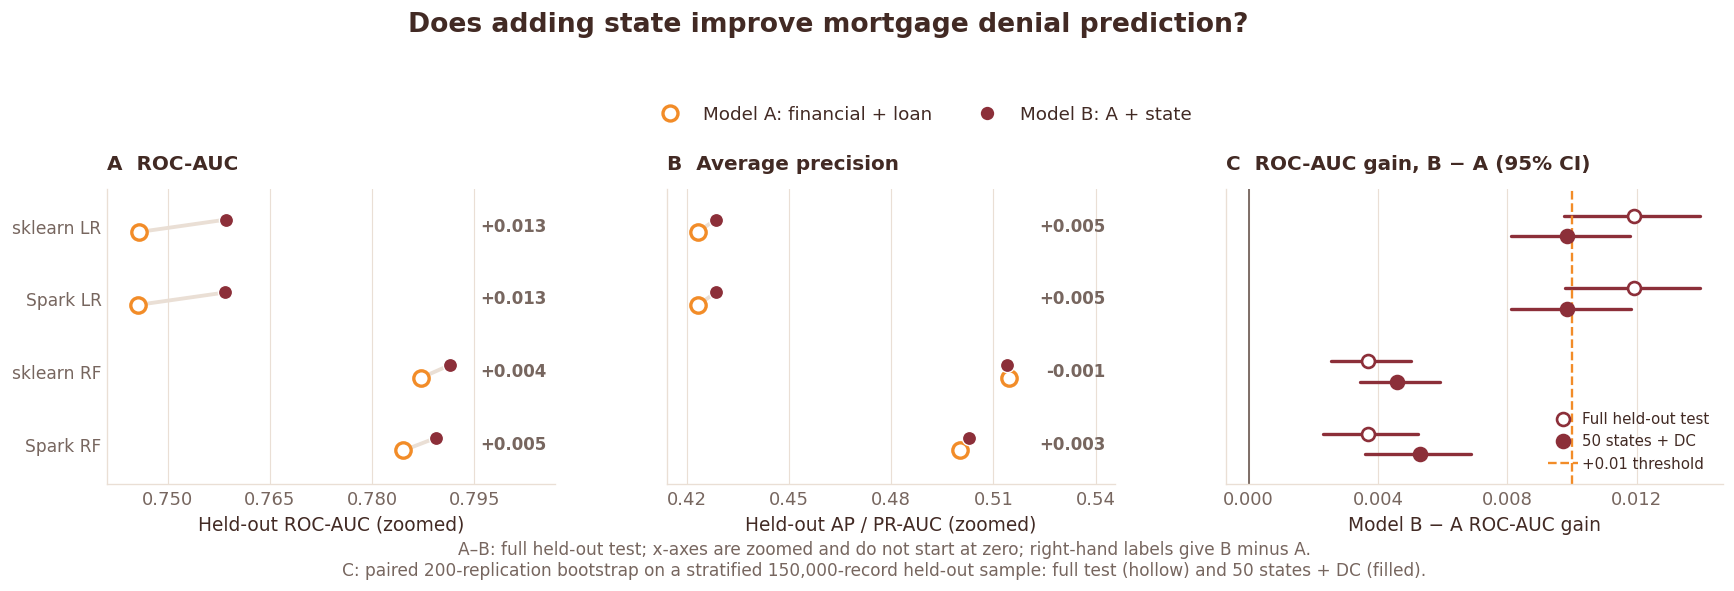

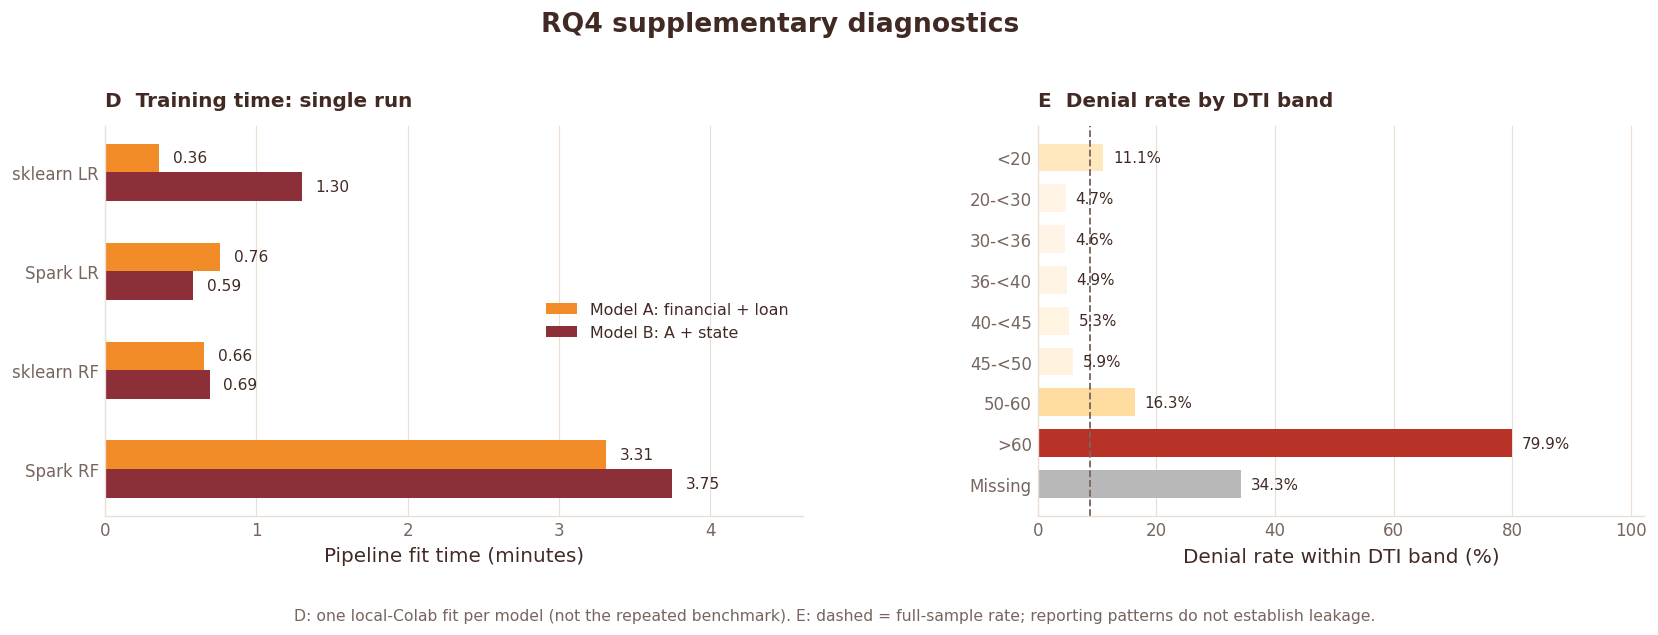

Horizontal multi-panel figures saved to: /content/drive/MyDrive/hmda/results/rq4
rq4_main_figure_ABC_predictive_value.png
rq4_appendix_figure_DE_diagnostics.png


In [19]:
# ============================================================
# GROUP 7 — TRUE HORIZONTAL MULTI-PANEL FIGURES
# All axes are drawn directly from data in a single Matplotlib figure.
# ============================================================
from matplotlib.ticker import MaxNLocator
figure_files = []

def store_rq4_figure(fig, filename):
    path = OUTPUT_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor=COLORS["white"])
    figure_files.append(path)
    plt.show()
    plt.close(fig)

framework_algorithm_order = [
    ("scikit-learn", "Logistic Regression"),
    ("Spark MLlib", "Logistic Regression"),
    ("scikit-learn", "Random Forest"),
    ("Spark MLlib", "Random Forest")
]

short_labels = ["sklearn LR", "Spark LR", "sklearn RF", "Spark RF"]

comparison_display = model_comparison.copy()
comparison_display["sort_index"] = [
    framework_algorithm_order.index((f, a))
    for f, a in zip(comparison_display["framework"], comparison_display["algorithm"])
]
comparison_display = comparison_display.sort_values("sort_index").reset_index(drop=True)
comparison_display["label"] = short_labels
assert len(comparison_display) == 4, "Expected four framework–algorithm comparisons."

bootstrap_figure = bootstrap_comparison.loc[
    bootstrap_comparison["evaluation_subset"] == "Full held-out test"].copy()
bootstrap_geo_figure = bootstrap_comparison.loc[
    bootstrap_comparison["evaluation_subset"] == "50 states + DC (test only)"].copy()
bootstrap_geo_figure["sort_index"] = [
    framework_algorithm_order.index((f, a))
    for f, a in zip(bootstrap_geo_figure["framework"], bootstrap_geo_figure["algorithm"])
]
bootstrap_geo_figure = bootstrap_geo_figure.sort_values("sort_index").reset_index(drop=True)
bootstrap_figure["sort_index"] = [
    framework_algorithm_order.index((f, a))
    for f, a in zip(bootstrap_figure["framework"], bootstrap_figure["algorithm"])
]
bootstrap_figure = bootstrap_figure.sort_values("sort_index").reset_index(drop=True)
assert len(bootstrap_figure) == 4, "Expected four bootstrap rows."

# ------------------------------------------------------------
# MAIN FIGURE — A, B AND C ALL IN ONE HORIZONTAL ROW
# ------------------------------------------------------------
fig, (ax_a, ax_b, ax_c) = plt.subplots(
    1, 3, figsize=(15.6, 5.4),
    gridspec_kw={"width_ratios": [1.10, 1.10, 1.22]}
)
fig.subplots_adjust(left=0.115, right=0.978, top=0.69,
                    bottom=0.235, wspace=0.24)
fig.suptitle(
    "Does adding state improve mortgage denial prediction?",
    fontsize=16, fontweight="bold", color=COLORS["text"], y=0.965
)

row_positions = np.arange(len(comparison_display))

def draw_paired_metric(ax, a_column, b_column, panel, title, xlabel,
                       show_row_labels=False):
    a_values = comparison_display[a_column].to_numpy(dtype=float)
    b_values = comparison_display[b_column].to_numpy(dtype=float)
    # Two distinguishable markers even if A and B have identical metric values.
    offset = 0.085
    for yy, a_val, b_val in zip(row_positions, a_values, b_values):
        ax.plot([a_val, b_val], [yy + offset, yy - offset],
                color=COLORS["grid"], linewidth=2.3, zorder=1)
    ax.scatter(a_values, row_positions + offset, s=85,
               facecolors="white", edgecolors=COLORS["orange"],
               linewidths=2.0, zorder=3)
    ax.scatter(b_values, row_positions - offset, s=72,
               facecolors=COLORS["burgundy"], edgecolors="white",
               linewidths=0.8, zorder=4)
    low = min(float(a_values.min()), float(b_values.min()))
    high = max(float(a_values.max()), float(b_values.max()))
    span = max(high - low, 0.012)
    ax.set_xlim(low - 0.10 * span, high + 0.34 * span)      # room on the right for the gain labels
    ax.set_ylim(len(row_positions) - 0.45, -0.5)
    ax.set_yticks(row_positions)
    ax.set_yticklabels(
        short_labels if show_row_labels else [], fontsize=10.3
    )
    ax.set_xlabel(xlabel, fontsize=11.2)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.tick_params(axis="x", labelsize=10.8)
    ax.set_title(f"{panel}  {title}", fontsize=12.0,
                 fontweight="bold", loc="left", pad=12)
    style_statistical_axes(ax, "x")
    ax.margins(y=0.08)


draw_paired_metric(ax_a, "model_A_roc_auc", "model_B_roc_auc",
                   "A", "ROC-AUC", "Held-out ROC-AUC (zoomed)", True)
draw_paired_metric(ax_b, "model_A_pr_auc", "model_B_pr_auc",
                   "B", "Average precision", "Held-out AP / PR-AUC (zoomed)")

# Small annotations make improvements / decreases legible at print size.
for ax, a_col, b_col in [
    (ax_a, "model_A_roc_auc", "model_B_roc_auc"),
    (ax_b, "model_A_pr_auc", "model_B_pr_auc")
]:
    changes = (
        comparison_display[b_col].to_numpy(dtype=float)
        - comparison_display[a_col].to_numpy(dtype=float)
    )
    x_left, x_right = ax.get_xlim()
    for yy, change in zip(row_positions, changes):
        ax.text(x_right - 0.02 * (x_right - x_left), yy,
                f"{change:+.3f}", ha="right", va="center",
                color=COLORS["secondary"], fontsize=10.0, fontweight="semibold")

# Panel C: bootstrap point estimates and percentile intervals are on
# the SAME fixed 150,000-record held-out subset (not the full-test point).
# two intervals per row: full held-out test (hollow, above) and 50 states + DC (filled, below)
for frame, dy, face, lab in [(bootstrap_figure, -0.14, "white", "Full held-out test"),
                             (bootstrap_geo_figure, 0.14, COLORS["burgundy"], "50 states + DC")]:
    pts = frame["bootstrap_subset_roc_auc_gain"].to_numpy(dtype=float)
    los = frame["roc_auc_ci_lower"].to_numpy(dtype=float)
    his = frame["roc_auc_ci_upper"].to_numpy(dtype=float)
    for yy, lo_, hi_ in zip(row_positions, los, his):
        ax_c.plot([lo_, hi_], [yy + dy, yy + dy], color=COLORS["burgundy"], linewidth=2.0,
                  solid_capstyle="round", zorder=2)
    ax_c.scatter(pts, row_positions + dy, s=60, facecolors=face, edgecolors=COLORS["burgundy"],
                 linewidths=1.6, zorder=4, label=lab)
ax_c.axvline(0, color=COLORS["secondary"], linewidth=1.1)
ax_c.axvline(PRACTICAL_ROC_AUC_GAIN, color=COLORS["orange"],
             linestyle="--", linewidth=1.4, label="+0.01 threshold")
ax_c.set_ylim(len(row_positions) - 0.45, -0.5)
ax_c.set_yticks(row_positions)
ax_c.set_yticklabels([])
ax_c.set_xlabel("Model B − A ROC-AUC gain", fontsize=11.2)
ax_c.xaxis.set_major_locator(MaxNLocator(nbins=5))
ax_c.tick_params(axis="x", labelsize=10.8)
ax_c.set_title("C  ROC-AUC gain, B − A (95% CI)", fontsize=12.0,
               fontweight="bold", loc="left", pad=12)
ax_c.legend(loc="lower right", frameon=False, fontsize=9.0, handletextpad=0.3)
style_statistical_axes(ax_c, "x")

from matplotlib.lines import Line2D
main_legend = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
           markeredgecolor=COLORS["orange"], markeredgewidth=2.0,
           markersize=9, label="Model A: financial + loan"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor=COLORS["burgundy"],
           markeredgecolor="white", markersize=9, label="Model B: A + state")
]
fig.legend(handles=main_legend, loc="upper center", bbox_to_anchor=(0.55, 0.845),
           ncol=2, frameon=False, fontsize=11.0)
fig.text(
    0.53, 0.095,
    "A–B: full held-out test; x-axes are zoomed and do not start at zero; right-hand labels give B minus A.\n"
    "C: paired 200-replication bootstrap on a stratified 150,000-record held-out sample: full test (hollow) and 50 states + DC (filled).",
    ha="center", fontsize=10.2, color=COLORS["secondary"]
)
store_rq4_figure(fig, "rq4_main_figure_ABC_predictive_value.png")

# ------------------------------------------------------------
# SUPPLEMENTARY FIGURE — D AND E SIDE BY SIDE, NOT STACKED
# ------------------------------------------------------------
fig, (ax_d, ax_e) = plt.subplots(
    1, 2, figsize=(15.2, 5.8),
    gridspec_kw={"width_ratios": [1.07, 0.93]}
)
fig.subplots_adjust(left=0.13, right=0.974, top=0.80,
                    bottom=0.24, wspace=0.36)
fig.suptitle("RQ4 supplementary diagnostics", fontsize=16,
             fontweight="bold", color=COLORS["text"], y=0.965)

# Panel D: measured single-fit training times; no Spark setup/I/O.
seconds_a = comparison_display["model_A_training_seconds"].to_numpy(dtype=float)
seconds_b = comparison_display["model_B_training_seconds"].to_numpy(dtype=float)
y = np.arange(len(comparison_display))
bar_height = 0.29
ax_d.barh(y - bar_height/2, seconds_a/60, height=bar_height,
          color=COLORS["orange"], label="Model A")
ax_d.barh(y + bar_height/2, seconds_b/60, height=bar_height,
          color=COLORS["burgundy"], label="Model B")
max_minutes = max(float(np.max(seconds_a)), float(np.max(seconds_b))) / 60
for yy, a, b in zip(y, seconds_a, seconds_b):
    ax_d.text(a/60 + max_minutes*0.024, yy-bar_height/2,
              f"{a/60:.2f}", fontsize=9.2, va="center")
    ax_d.text(b/60 + max_minutes*0.024, yy+bar_height/2,
              f"{b/60:.2f}", fontsize=9.2, va="center")
ax_d.set_xlim(0, max_minutes*1.23)
ax_d.set_yticks(y)
ax_d.set_yticklabels(short_labels, fontsize=10)
ax_d.invert_yaxis()
ax_d.set_xlabel("Pipeline fit time (minutes)")
ax_d.set_title("D  Training time: single run", fontsize=12.0,
               fontweight="bold", loc="left", pad=12)
style_statistical_axes(ax_d, "x")

# Panel E: observed denial rate in each DTI band (including Missing).
dti_display = dti_band_denial_rates.copy()
dti_display["label"] = dti_display["dti_band"].astype(str)
rate_percent = dti_display["denial_rate"].to_numpy(dtype=float)*100
is_missing = dti_display["label"].isin(DTI_MISSING_MARKERS).to_numpy()
normalizer = Normalize(vmin=float(np.min(rate_percent)),
                       vmax=float(np.max(rate_percent)))
bar_colors = [
    COLORS["missing"] if is_na else HEATMAP_CMAP(normalizer(rate))
    for rate, is_na in zip(rate_percent, is_missing)
]
y_dti = np.arange(len(dti_display))
ax_e.barh(y_dti, rate_percent, height=0.68, color=bar_colors)
ax_e.axvline(float(model_data["denied"].mean()*100),
             color=COLORS["secondary"], linestyle="--", linewidth=1.1,
             label="Full-sample denial rate")
for yy, rate in zip(y_dti, rate_percent):
    ax_e.text(rate + max(rate_percent)*0.021, yy,
              f"{rate:.1f}%", va="center", fontsize=9.1)
ax_e.set_xlim(0, float(np.max(rate_percent))*1.28)
ax_e.set_yticks(y_dti)
ax_e.set_yticklabels(dti_display["label"], fontsize=10)
ax_e.invert_yaxis()
ax_e.set_xlabel("Denial rate within DTI band (%)")
ax_e.set_title("E  Denial rate by DTI band", fontsize=12.0,
               fontweight="bold", loc="left", pad=12)
style_statistical_axes(ax_e, "x")

handles_d, _ = ax_d.get_legend_handles_labels()
ax_d.legend(handles_d, ["Model A: financial + loan", "Model B: A + state"],
            loc="center right", frameon=False, fontsize=9.5)
fig.text(
    0.53, 0.09,
    "D: one local-Colab fit per model (not the repeated benchmark). "
    "E: dashed = full-sample rate; reporting patterns do not establish leakage.",
    ha="center", fontsize=9.4, color=COLORS["secondary"]
)
store_rq4_figure(fig, "rq4_appendix_figure_DE_diagnostics.png")

print("Horizontal multi-panel figures saved to:", OUTPUT_DIR)
for path in figure_files:
    print(path.name)


## 20. Export RQ4 tables, predictions and figures

All outputs are written to a new folder. The original cleaned Parquet file and the RQ3 results are not modified.

In [20]:
# Export result tables.
all_results.to_csv(
    OUTPUT_DIR / "rq4_all_model_metrics.csv",
    index=False
)

model_comparison.to_csv(
    OUTPUT_DIR / "rq4_model_A_vs_B_and_metro_comparison.csv",
    index=False
)

bootstrap_comparison.to_csv(
    OUTPUT_DIR / "rq4_paired_bootstrap_A_vs_B.csv",
    index=False
)

training_time_comparison.to_csv(
    OUTPUT_DIR / "rq4_training_time_comparison.csv",
    index=False
)

runtime_overhead.to_csv(
    OUTPUT_DIR / "rq4_spark_setup_and_io_times.csv",
    index=False
)

split_summary.to_csv(
    OUTPUT_DIR / "rq4_train_test_split_summary.csv",
    index=False
)

# Combine all held-out probabilities into one paired prediction file.
prediction_output = test_df[["row_id", "denied"]].copy()

for framework_name, prediction_dict in [
    ("sklearn", sklearn_predictions),
    ("spark", spark_predictions)
]:
    for (spec_name, algorithm), prediction_table in prediction_dict.items():
        algorithm_tag = (
            "logistic" if algorithm == "Logistic Regression"
            else "random_forest"
        )
        column_name = f"{framework_name}_{algorithm_tag}_model_{spec_name}"

        aligned = prediction_table[["row_id", "score"]].rename(
            columns={"score": column_name}
        )

        prediction_output = prediction_output.merge(
            aligned,
            on="row_id",
            how="left",
            validate="one_to_one"
        )

prediction_output.to_parquet(
    SPLIT_DIR / "rq4_heldout_test_predictions.parquet",     # local copy (~47 MB), not part of results/
    index=False,
    engine="pyarrow"
)

# Figures were already displayed and exported in Section 19.
print("RQ4 output directory:", OUTPUT_DIR)
print("Saved figures:")
for path in figure_files:
    print(path.name)

train_test_diagnostics.to_csv(
    OUTPUT_DIR / "rq4_train_vs_test_diagnostics.csv", index=False
)
geography_sensitivity.to_csv(
    OUTPUT_DIR / "rq4_50_states_dc_geography_sensitivity.csv", index=False
)
train_eval_summary.to_csv(
    OUTPUT_DIR / "rq4_train_evaluation_subset_summary.csv", index=False
)


# Audit and targeted robustness outputs.
missingness_audit.to_csv(
    OUTPUT_DIR / "rq4_predictor_missingness_by_outcome.csv", index=False
)
dti_band_denial_rates.to_csv(
    OUTPUT_DIR / "rq4_dti_band_denial_rates.csv", index=False
)
dti_missing_sensitivity.to_csv(
    OUTPUT_DIR / "rq4_dti_observed_lr_refit_details.csv", index=False
)
dti_missing_sensitivity_summary.to_csv(
    OUTPUT_DIR / "rq4_dti_observed_lr_refit_summary.csv", index=False
)

# Verify model-fit timing is taken from exactly one authoritative results table.
for _, item in model_comparison.iterrows():
    for specification in ["A", "B", "C"]:
        observed = all_results.loc[
            (all_results["framework"] == item["framework"]) &
            (all_results["algorithm"] == item["algorithm"]) &
            (all_results["model_specification"] == specification),
            "training_seconds"
        ]
        if len(observed) != 1 or not np.isclose(
            float(observed.iloc[0]),
            float(item[f"model_{specification}_training_seconds"]),
            rtol=0, atol=1e-10
        ):
            raise AssertionError("Training times differ between the results tables.")

import json, sys, sklearn, pyarrow
run_manifest = {
    "run_started_utc": RUN_STARTED_UTC,
    "input_file": DATA_PATH.name,
    "analytical_records": int(len(model_data)),
    "geographic_reference_records_50_states_dc": int(geo_reference_records),
    "geographic_reference_raw_denial_rate": float(geo_reference_rate),
    "train_records": int(len(train_df)),
    "heldout_test_records": int(len(test_df)),
    "seed": RANDOM_SEED,
    "split": "stratified 80/20",
    "main_models": ["A", "B", "C"],
    "frameworks": ["scikit-learn", "Spark MLlib"],
    "algorithms": ["Logistic Regression", "Random Forest"],
    "python_version": sys.version.split()[0],
    "pandas_version": pd.__version__,
    "sklearn_version": sklearn.__version__,
    "pyspark_version": spark.version,
    "pyarrow_version": pyarrow.__version__,
    "spark_session_startup_s": float(SPARK_STARTUP_SECONDS),
    "spark_split_io_s": float(SPARK_SPLIT_IO_SECONDS),
    "timing_repetitions_per_core_model": 1,
    "benchmark_note": "Descriptive one-fit timings; not the group's five-run scale benchmark",
    "dti_sensitivity": "scikit-learn LR A/B only, train and test filtered to observed DTI",
}
(OUTPUT_DIR / "rq4_run_manifest.json").write_text(
    json.dumps(run_manifest, indent=2), encoding="utf-8"
)
print("Training-time table consistency: PASSED")
print("Run manifest saved.")

RQ4 output directory: /content/drive/MyDrive/hmda/results/rq4
Saved figures:
rq4_main_figure_ABC_predictive_value.png
rq4_appendix_figure_DE_diagnostics.png
Training-time table consistency: PASSED
Run manifest saved.


## 21. Final RQ4 summary

Interpretation should focus on whether adding state improves held-out ROC-AUC and PR-AUC beyond the financial and loan characteristics in Model A. A ROC-AUC gain of at least 0.01 meets the proposal's prespecified practical-significance threshold.

Precision, recall and F1 refer to the denied class at a fixed 0.50 threshold. Because the target is imbalanced, accuracy alone is not sufficient.

The metro-status model is a separate sensitivity analysis. Model results do not establish causation, discrimination or suitability for individual lending decisions.

In [21]:
print("=" * 76)
print("RQ4 — FINAL PREDICTIVE ANALYSIS SUMMARY")
print("=" * 76)

print(f"Total in-scope records: {len(model_data):,}")
print(f"Training records: {len(train_df):,}")
print(f"Held-out test records: {len(test_df):,}")
print(f"Training denial rate: {train_df['denied'].mean():.4%}")
print(f"Test denial rate: {test_df['denied'].mean():.4%}")
print(f"Always-non-denied test accuracy: {baseline_metrics['accuracy']:.4%}")
print(f"Always-non-denied test ROC-AUC: {baseline_metrics['roc_auc']:.4f}")
print(f"Always-non-denied test PR-AUC: {baseline_metrics['pr_auc_average_precision']:.4f}")

print("\nModel A vs. Model B:")
display(
    model_comparison[
        [
            "framework",
            "algorithm",
            "model_A_roc_auc",
            "model_B_roc_auc",
            "roc_auc_gain_B_minus_A",
            "model_A_pr_auc",
            "model_B_pr_auc",
            "pr_auc_gain_B_minus_A",
            "practical_roc_auc_gain_at_least_001"
        ]
    ].style.format({
        "model_A_roc_auc": "{:.4f}",
        "model_B_roc_auc": "{:.4f}",
        "roc_auc_gain_B_minus_A": "{:+.4f}",
        "model_A_pr_auc": "{:.4f}",
        "model_B_pr_auc": "{:.4f}",
        "pr_auc_gain_B_minus_A": "{:+.4f}"
    })
)

print("\nPaired bootstrap confidence intervals:")
display(bootstrap_comparison)

print("\nTraining-time comparison:")
display(training_time_comparison)

print("\nSpark setup and data I/O were measured separately:")
display(runtime_overhead)

print("\nOutput directory:", OUTPUT_DIR)
print("RQ4 analysis completed.")

print("\nTrain-set subset vs. full held-out test diagnostics:")
display(train_test_diagnostics)
print("\nGeographic sensitivity: 50 states + DC, test-only subgroup:")
display(geography_sensitivity)
print("Train metrics describe a fixed training subset; test metrics describe all held-out records.")

print("\nPredictor missingness by outcome:")
display(missingness_audit[
    ["variable", "missing_non_denied_pct", "missing_denied_pct",
     "missing_rate_difference_denied_minus_non_denied_pp"]
])
print("\nObserved-DTI refit sensitivity (sklearn LR A/B only):")
display(dti_missing_sensitivity_summary)
print("\nModel-fit times are single-run descriptive observations, not the group benchmark.")
print("Geographic reference: 50 states + DC; main RQ4 model training: full in-scope sample.")
print("All figures and tables were generated by this run.")

RQ4 — FINAL PREDICTIVE ANALYSIS SUMMARY
Total in-scope records: 3,140,857
Training records: 2,512,685
Held-out test records: 628,172
Training denial rate: 8.8066%
Test denial rate: 8.8067%
Always-non-denied test accuracy: 91.1933%
Always-non-denied test ROC-AUC: 0.5000
Always-non-denied test PR-AUC: 0.0881

Model A vs. Model B:


,framework,algorithm,model_A_roc_auc,model_B_roc_auc,roc_auc_gain_B_minus_A,model_A_pr_auc,model_B_pr_auc,pr_auc_gain_B_minus_A,practical_roc_auc_gain_at_least_001
0,scikit-learn,Logistic Regression,0.7458,0.7585,+0.0128,0.4233,0.4285,+0.0052,True
1,scikit-learn,Random Forest,0.7872,0.7914,+0.0041,0.5145,0.5139,-0.0007,False
2,Spark MLlib,Logistic Regression,0.7457,0.7585,+0.0128,0.4234,0.4286,+0.0052,True
3,Spark MLlib,Random Forest,0.7846,0.7893,+0.0047,0.5002,0.5027,+0.0025,False



Paired bootstrap confidence intervals:


,evaluation_subset,framework,algorithm,roc_auc_gain_B_minus_A,bootstrap_subset_roc_auc_gain,roc_auc_ci_lower,roc_auc_ci_upper,pr_auc_gain_B_minus_A,bootstrap_subset_pr_auc_gain,pr_auc_ci_lower,pr_auc_ci_upper,bootstrap_replications,bootstrap_evaluation_records,roc_auc_gain_at_least_001,roc_auc_ci_lower_at_least_001,roc_auc_ci_excludes_zero
0,Full held-out test,scikit-learn,Logistic Regression,0.012755,0.011905,0.009763,0.013949,0.005224,0.004669,0.001855,0.006955,200,150000,True,False,True
1,Full held-out test,scikit-learn,Random Forest,0.004123,0.003677,0.002553,0.005031,-0.000686,-0.001821,-0.003543,0.000029,200,150000,False,False,True
2,Full held-out test,Spark MLlib,Logistic Regression,0.012771,0.011924,0.009779,0.013970,0.005203,0.004647,0.001824,0.006920,200,150000,True,False,True
3,Full held-out test,Spark MLlib,Random Forest,0.004703,0.003695,0.002294,0.005235,0.002547,0.001155,-0.000239,0.002672,200,150000,False,False,True
4,50 states + DC (test only),scikit-learn,Logistic Regression,0.010430,0.009837,0.008112,0.011810,0.000276,0.000575,-0.001462,0.002585,200,150000,True,False,True
5,50 states + DC (test only),scikit-learn,Random Forest,0.004147,0.004581,0.003435,0.005914,-0.000932,-0.000127,-0.001765,0.001404,200,150000,False,False,True
6,50 states + DC (test only),Spark MLlib,Logistic Regression,0.010444,0.009851,0.008118,0.011814,0.000258,0.000554,-0.001487,0.002563,200,150000,True,False,True
7,50 states + DC (test only),Spark MLlib,Random Forest,0.005003,0.005287,0.003605,0.006866,0.002422,0.002085,0.000468,0.003888,200,150000,False,False,True



Training-time comparison:


,framework,algorithm,model_specification,training_seconds,roc_auc,pr_auc_average_precision
0,Spark MLlib,Logistic Regression,A,45.653953,0.745736,0.423369
1,scikit-learn,Logistic Regression,A,21.441854,0.745784,0.423264
2,Spark MLlib,Logistic Regression,B,35.134073,0.758507,0.428572
3,scikit-learn,Logistic Regression,B,78.007336,0.758539,0.428488
4,Spark MLlib,Logistic Regression,C,33.864428,0.745830,0.422906
5,scikit-learn,Logistic Regression,C,22.718350,0.745865,0.422840
6,Spark MLlib,Random Forest,A,198.816189,0.784619,0.500192
7,scikit-learn,Random Forest,A,39.326287,0.787249,0.514540
8,Spark MLlib,Random Forest,B,224.897396,0.789322,0.502739
9,scikit-learn,Random Forest,B,41.632463,0.791372,0.513854


... (7 outputs left out)

,variable,missing_non_denied_pct,missing_denied_pct,missing_rate_difference_denied_minus_non_denied_pp
0,income,0.989019,3.608046,2.619027
1,loan_amount,0.000000,0.000000,0.000000
2,property_value,0.544226,5.008243,4.464017
3,combined_loan_to_value_ratio,2.862212,5.656462,2.794250
4,loan_term,0.137942,1.161950,1.024008
5,dti_band,0.576660,3.116730,2.540070
6,loan_type,0.000000,0.000000,0.000000
7,state_code,0.097443,1.892597,1.795155
8,metro_flag,0.000000,0.000000,0.000000



Observed-DTI refit sensitivity (sklearn LR A/B only):


,framework,evaluation_population,primary_full_test_lr_auc_gain_B_minus_A,original_fit_observed_dti_auc_gain_B_minus_A,refit_observed_dti_auc_gain_B_minus_A,original_fit_observed_dti_pr_auc_gain_B_minus_A,refit_observed_dti_pr_auc_gain_B_minus_A
0,scikit-learn,Held-out applications with observed DTI,0.012755,0.013216,0.01327,0.006351,0.00623



Model-fit times are single-run descriptive observations, not the group benchmark.
Geographic reference: 50 states + DC; main RQ4 model training: full in-scope sample.
All figures and tables were generated by this run.


## 22. Limitations and interpretation

- The public 2024 LAR does not provide an application date suitable for chronological train/test splitting; the analysis therefore uses a seeded, stratified random split.
- The model predicts denial within the proposal's restricted in-scope sample, not for all HMDA records or all mortgage applicants.
- Missing income, CLTV, property value and loan-term values are median-imputed without missingness indicators. DTI's existing `Missing` band is retained. Outcome-related missingness may still affect predictive performance.
- HMDA does not provide all underwriting information, such as a complete credit-risk profile or all lender-specific decision rules.
- State and metro status may capture differences in local markets, reporting patterns and applicant composition. Their predictive contribution is not a causal geographic effect.
- Race, ethnicity, sex and age are excluded from model inputs. This does not by itself establish that predictions are unbiased; proxy effects and subgroup performance require separate, carefully governed analysis.
- Training performance is reported on a fixed stratified 150,000-record subset of the training sample, not the complete training sample; the primary test metrics use all held-out records.
- State-code robustness is assessed on the 50-state-plus-DC subset of the held-out sample without retraining. This tests whether conclusions are driven by unassigned or territory codes, but does not reproduce an exclusively state-plus-DC training design.
- The model is for research and analytical risk ranking only. It must not be used to approve, deny, price or otherwise make decisions about individual borrowers.
- Scikit-learn and Spark MLlib use different optimization solvers, category-indexing conventions and tree implementations. Preprocessing is aligned as closely as feasible, but fitted models are not expected to be identical.
- Paired bootstrap confidence intervals are based on a fixed 150,000-record stratified test subsample. They are supplementary to the full-test point estimates and should not be described as full-test confidence intervals.
- Each model configuration is timed once. Local-mode Spark training times depend on the Colab runtime and should not be generalized to a distributed Spark cluster.

- In a **separate** supplementary scikit-learn LR sensitivity, Models A/B are refitted using only training records with reported DTI, then evaluated on the matching held-out test subgroup. This does not replace the full-sample estimates or the cross-framework experiment.
- DTI missingness by denial outcome is descriptive; HMDA reporting rules and information timing make it unsuitable to claim that a missing DTI band is necessarily an outcome leak. The same caveat applies to other underwriting fields and to unknown geographic codes.
- Denial rates for states and D.C. should be compared with the **50-states-plus-DC reference**; the overall in-scope denial rate (8.81%) pertains to the full RQ4 classification population. ROC-AUC and average precision are not denial-rate gaps and must not be offset against either reference rate.